# 127 · attention layers (transformer3)
Every attention layer of a `transformer3` run: the freq stage (18 bands attend to each other, within each laser) and the laser stage (100 lasers attend to each other).

**Settings** (the only cell to edit): `RUNS` = list of `runs/<run>` transformer3 runs (latest checkpoint each): freq-stage figures show every run, all other figures the last one. `SAMPLE` = an eval sample `{position:06d}-{speaker}`.
`ALL_EVAL = True` averages over every eval sample (or only `EVAL_SPLITS`, e.g. `["gastro/vase"]`; `MAX_SAMPLES` caps it) instead of one sample.
`HEADS = "mean"` averages the heads, `"all"` shows each head. `QUERY_LASERS` = lasers (row, col) for the spatial view. `--readout cls` runs get an extra `cls` row/col.

In [1]:
RUNS = ["base300-v1", "cls-v2"]      # runs/<run> transformer3 runs; freq figures compare all of them, every other figure uses the LAST one
SAMPLE = "003091-1"          # an eval sample id (falls back to the first eval sample if missing)
ALL_EVAL = False             # True: average over all eval samples (or over EVAL_SPLITS)
EVAL_SPLITS = None           # None = all eval splits; or e.g. ["gastro/vase", "cardboard/cube"]
MAX_SAMPLES = None           # cap for ALL_EVAL speed
HEADS = "mean"               # "mean" over heads or "all"
DEVICE = "auto"              # "auto" = cuda if >= 3 GB free, else cpu
QUERY_LASERS = [(0, 0), (0, 9), (9, 0), (9, 9), (5, 5)]  # (row, col) on the 10x10 laser grid
BATCH = 32

**Load + run**: data from the MDS cache training uses; `attention(run)` loads a run (args.json + latest checkpoint, eval mode: no augs, no token dropout),
hooks every `Block` to recompute `softmax(rot(q) rot(k)ᵀ/√hd + mask)` per head (assert: reproduces the block's output), streams the samples (one, or `ALL_EVAL` in batches)
keeping only running sums of the per-layer maps (freq: mean over lasers) and per-sample entropies, then frees the model.

In [2]:
import os, sys, io, json, math, time, inspect, contextlib, hashlib, gc
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, torch, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9
from arch.transformer3 import Transformer3, rotate
torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = False
if DEVICE == "auto": DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.mem_get_info()[0] >= 3e9 else "cpu"

ARGS = {run: json.load(open(f"runs/{run}/args.json")) for run in RUNS}
assert all(a["model"] == "transformer3" for a in ARGS.values()), {r: a["model"] for r, a in ARGS.items()}
a0 = ARGS[RUNS[-1]]
assert all((a["window"], a["height"], a["width"]) == (a0["window"], a0["height"], a0["width"]) for a in ARGS.values()), "runs need the same data cache"
with contextlib.redirect_stdout(io.StringIO()): samples, idxs = D9.load_splits()
dirs, metas = list(samples), list(samples.values())
m0 = metas[0]
mds = D9.MDS / (f"cache_{a0['window']}_{a0['height']}x{a0['width']}_" + hashlib.sha1(repr((D9.MDS_VERSION, a0["window"], a0["height"], a0["width"], [str(d) for d in samples], idxs)).encode()).hexdigest()[:12])
ds = D9.VibrationDataset(mds, metas, set())                       # the MDS cache training reads: rows in `metas` order
_, NF, NC = ds[0]["fft"].shape
info = dict(n_laser_rows=m0["n_rows"], n_laser_cols=m0["n_cols"], n_freqs=NF, n_channels=NC, freq_range=(float(m0["min_freq"]), float(m0["max_freq"])))

splits = {n[5:]: ids for n, ids in idxs.items() if n != "train"}
EVAL = sorted({i for n, ids in splits.items() if EVAL_SPLITS is None or n in EVAL_SPLITS for i in ids})
if not ALL_EVAL and not any(metas[i]["sample_id"] == SAMPLE for i in EVAL): SAMPLE = metas[EVAL[0]]["sample_id"]; print("SAMPLE not in eval -> using", SAMPLE)
i0 = next(i for i in EVAL if metas[i]["sample_id"] == SAMPLE)
split0 = next(n for n, ids in splits.items() if i0 in ids)
ids = EVAL[:MAX_SAMPLES] if ALL_EVAL else [i0]
WHAT = f"mean over {len(ids)} eval samples" + (f" ({', '.join(EVAL_SPLITS)})" if EVAL_SPLITS else "") if ALL_EVAL else f"sample {SAMPLE} ({split0})"

def keep_attention(blk, inp, out):
    x, rope, keep = inp
    N, T, D = x.shape
    q, k, v = blk.qkv(blk.n1(x)).view(N, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)    # 3 x (N,H,T,hd), as Block.forward
    q, k = rotate(q, rope), rotate(k, rope)
    s = q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])
    blk.att = s.masked_fill(~keep[:, None, None].bool(), -torch.inf).softmax(-1)     # (N,H,T,T) row = query, col = key
    y = x + blk.o((blk.att @ v).transpose(1, 2).reshape(N, T, D))
    blk.err = (y + blk.mlp(blk.n2(y)) - out).abs().max().item()

def entropy(a): return -(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(a.shape[-1])  # normalized, per query row

def attention(run):
    """one run over `ids` -> dict: tag, cls, F_ATT / L_ATT per layer (H,T,T) means, F_ENT / L_ENT (n,layers,H) token-query entropy, *_CLS = cls-query entropy, y_pred"""
    args = ARGS[run]
    ckpt = max(Path(f"runs/{run}/checkpoints").glob("ep*.pt"), key=lambda p: int(p.name.split("-")[0][2:]))
    sd = torch.load(ckpt, map_location="cpu", weights_only=False, mmap=True)["state"]["model"]
    sd = {k.removeprefix("_orig_mod."): v for k, v in sd.items()}
    model = Transformer3(info | dict(objects=["?"] * (len(sd["object_head.2.bias"]) + 1), boxes=["?"] * len(sd["box_head.2.bias"])),   # only the head sizes matter
                         **{k: v for k, v in args.items() if k in inspect.signature(Transformer3).parameters})
    model.load_state_dict(sd); model.to(DEVICE).eval(); del sd
    f_blocks, l_blocks = list(model.encoder.freq_enc.freqs), list(model.encoder.laser_enc.lasers)
    for blk in f_blocks + l_blocks: blk.register_forward_hook(keep_attention)
    cls, NL = int(args["readout"] == "cls"), model.encoder.L
    f_sum, l_sum, f_ent, l_ent, t0 = [0] * len(f_blocks), [0] * len(l_blocks), [], [], time.time()
    for j in range(0, len(ids), BATCH):
        b = [ds[i] for i in ids[j:j + BATCH]]
        with torch.no_grad(): out = model(dict(fft=torch.stack([r["fft"] for r in b]).to(DEVICE)))
        B = len(b)
        assert max(blk.err for blk in f_blocks + l_blocks) < 1e-3, [blk.err for blk in f_blocks + l_blocks]
        fe, le = [], []
        for l, blk in enumerate(f_blocks):
            a = blk.att.view(B, NL, *blk.att.shape[1:])           # (B,lasers,H,T,T)
            f_sum[l] = f_sum[l] + a.mean(1).sum(0).cpu(); e = entropy(a); fe.append(torch.stack([e[..., cls:].mean((1, 3)), e[..., 0].mean(1)], -1))
        for l, blk in enumerate(l_blocks):
            l_sum[l] = l_sum[l] + blk.att.sum(0).cpu(); e = entropy(blk.att); le.append(torch.stack([e[..., cls:].mean(2), e[..., 0]], -1))
        f_ent.append(torch.stack(fe, 1).cpu()); l_ent.append(torch.stack(le, 1).cpu())
        for blk in f_blocks + l_blocks: del blk.att
    n, ep = len(ids), int(ckpt.name.split("-")[0][2:])
    FE, LE = torch.cat(f_ent).numpy(), torch.cat(l_ent).numpy()  # (n,layers,H,2)
    r = dict(tag=f"{run}@{ep}", cls=cls, heads=f_blocks[0].h, F_ATT=[s / n for s in f_sum], L_ATT=[s / n for s in l_sum],
             F_ENT=FE[..., 0], F_ENT_CLS=FE[..., 1], L_ENT=LE[..., 0], L_ENT_CLS=LE[..., 1], y_pred=out["mask_pred"][0].cpu().numpy(), grid=model.grid_rc, NB=model.encoder.n_bands, NL=NL)
    print(f"{r['tag']} · {ckpt.name} · {DEVICE} · freq {len(f_blocks)} layers, laser {len(l_blocks)} layers, {r['heads']} heads, cls = {bool(cls)} · {n} samples in {time.time() - t0:.1f} s"
          + (f" (all {len(EVAL)} eval ≈ {(time.time() - t0) / n * len(EVAL) / 60:.1f} min)" if ALL_EVAL else ""))
    del model, f_blocks, l_blocks, out; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return r

RES = {run: attention(run) for run in RUNS}
# the last run feeds every non-freq figure
last = RES[RUNS[-1]]
TAG, CLS, F_ATT, L_ATT, F_ENT, F_ENT_CLS, L_ENT, L_ENT_CLS = (last[k] for k in ("tag", "cls", "F_ATT", "L_ATT", "F_ENT", "F_ENT_CLS", "L_ENT", "L_ENT_CLS"))
(R, C), NB, NL = last["grid"], last["NB"], last["NL"]
BAND_HZ = np.linspace(*info["freq_range"], info["n_freqs"])[a0["bins_per_band"] // 2::a0["bins_per_band"]]  # band centres
band_lab = (["cls"] if CLS else []) + [f"{h:.0f}" for h in BAND_HZ]
y_true, y_pred = ds[i0]["mask_true"].numpy(), last["y_pred"]

base300-v1@300 · ep300-ba3000-rank0.pt · cuda · freq 4 layers, laser 8 layers, 8 heads, cls = False · 1 samples in 0.5 s


cls-v2@300 · ep300-ba3000-rank0.pt · cuda · freq 4 layers, laser 8 layers, 8 heads, cls = True · 1 samples in 0.4 s


## 1 · freq stage: band-to-band attention (every run)
One figure per run. Rows = query band, cols = key band, averaged over the 100 lasers. Colour scale shared across a run's panels.

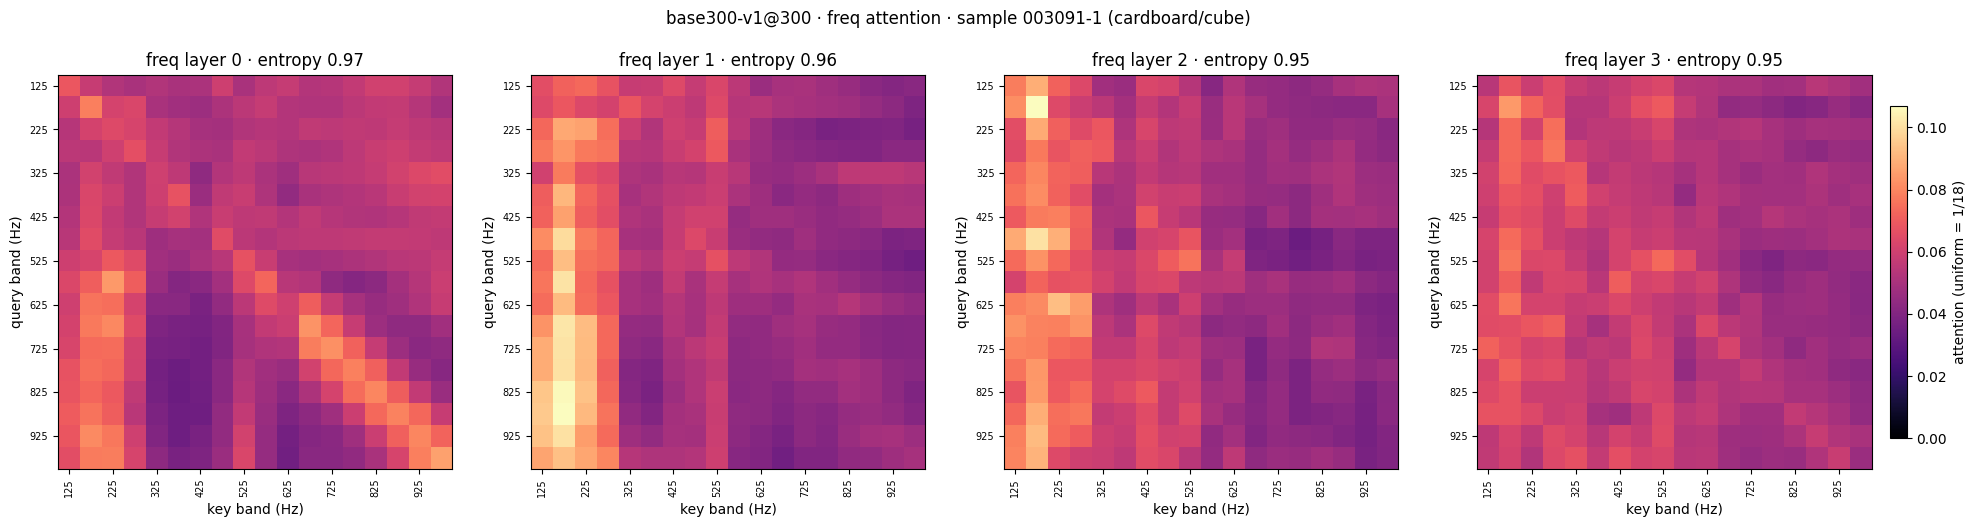

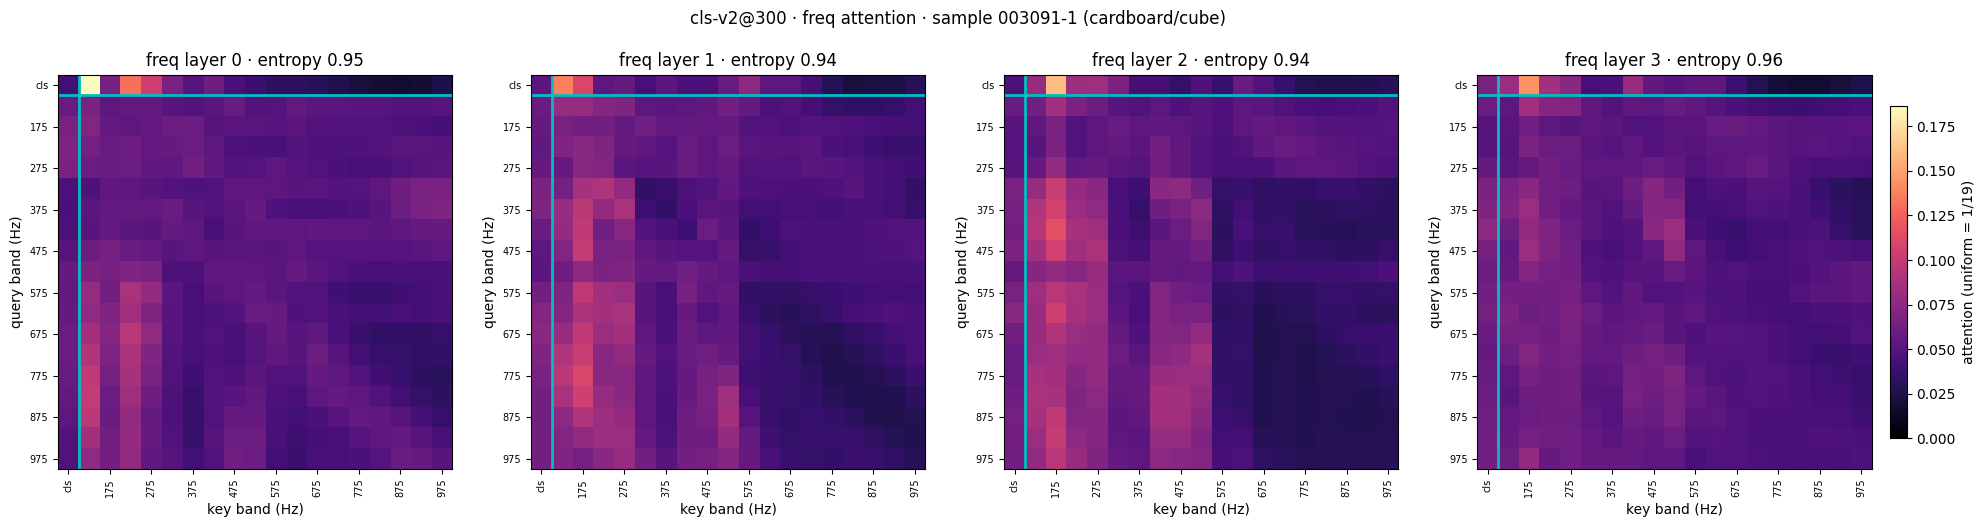

In [3]:
def heads_of(a): return [a.mean(0)] if HEADS == "mean" else list(a)
for run, r in RES.items():
    lab = (["cls"] if r["cls"] else []) + [f"{h:.0f}" for h in BAND_HZ]
    nh, nl = 1 if HEADS == "mean" else r["heads"], len(r["F_ATT"])
    fig, axs = plt.subplots(nh, nl, figsize=(6 * nl, 5.4 * nh), squeeze=False)
    vmax = max(float(m.max()) for a in r["F_ATT"] for m in heads_of(a))
    for l, a in enumerate(r["F_ATT"]):
        for h, m in enumerate(heads_of(a)):
            ax = axs[h, l]
            im = ax.imshow(m, cmap="magma", vmin=0, vmax=vmax, interpolation="nearest")
            if r["cls"]: ax.axhline(.5, color="c", lw=2); ax.axvline(.5, color="c", lw=2)   # cls | bands
            e = r["F_ENT"][:, l].mean() if HEADS == "mean" else r["F_ENT"][:, l, h].mean()
            ax.set_title(f"freq layer {l}" + ("" if HEADS == "mean" else f" · head {h}") + f" · entropy {e:.2f}")
            ax.set_xticks(range(0, len(lab), 2), lab[::2], rotation=90, fontsize=7); ax.set_yticks(range(0, len(lab), 2), lab[::2], fontsize=7)
            ax.set_xlabel("key band (Hz)"); ax.set_ylabel("query band (Hz)")
    fig.colorbar(im, ax=axs, shrink=.8, fraction=.015, pad=.01, label=f"attention (uniform = 1/{r['F_ATT'][0].shape[-1]})")
    fig.suptitle(f"{r['tag']} · freq attention · {WHAT}"); plt.show()

Attention each key band receives from the band queries (mean over heads, lasers, query bands; [cls] row/col left out and renormalized over the 18 bands, so runs compare). One panel per layer, one line per run.

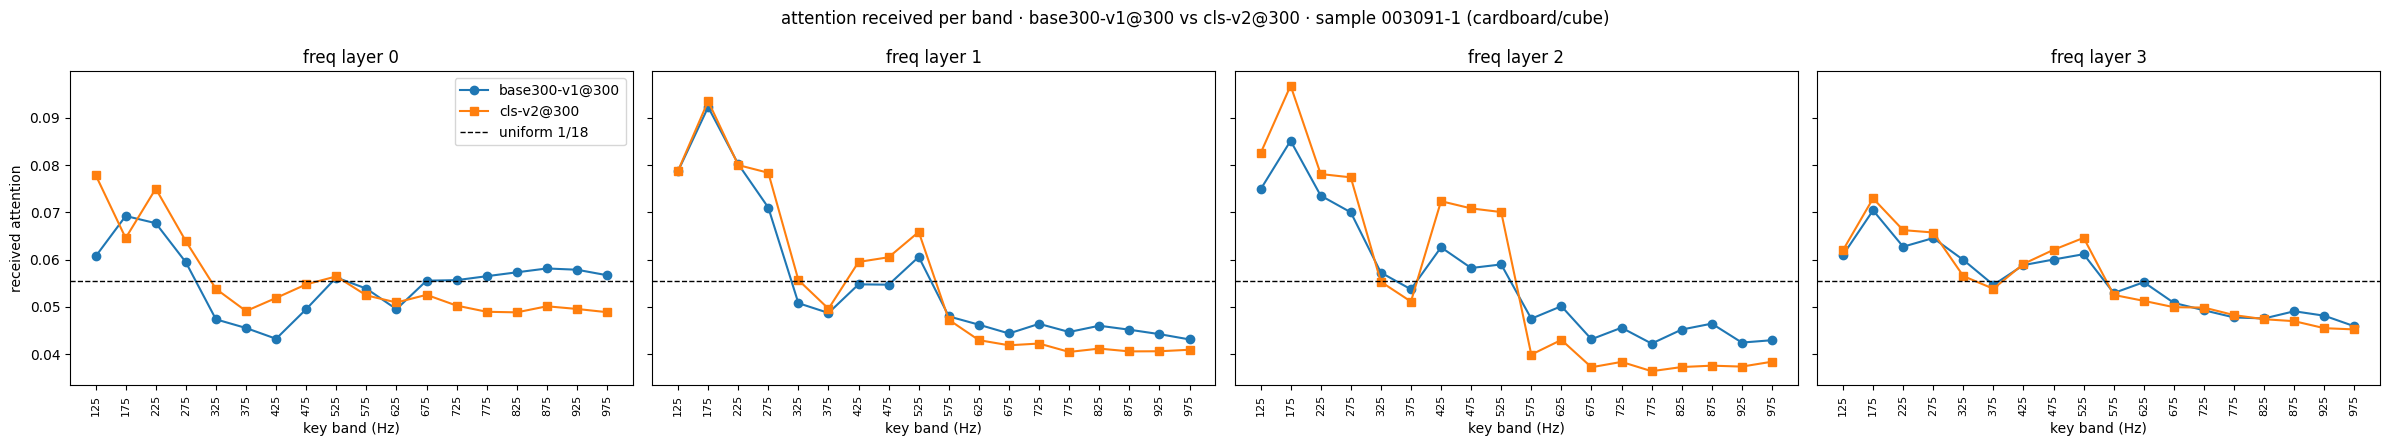

In [4]:
nl = max(len(r["F_ATT"]) for r in RES.values())
fig, axs = plt.subplots(1, nl, figsize=(6 * nl, 4.5), squeeze=False, sharey=True)
for k, (run, r) in enumerate(RES.items()):
    for l, a in enumerate(r["F_ATT"]):
        m = a.mean(0)[r["cls"]:, r["cls"]:]                         # band queries x band keys
        recv = (m / m.sum(-1, keepdim=True)).mean(0).numpy()
        axs[0, l].plot(recv, "os^vD"[k % 5] + "-", color=f"C{k}", label=r["tag"])
for l, ax in enumerate(axs[0]):
    ax.axhline(1 / NB, color="k", ls="--", lw=1, label="uniform 1/18" if l == 0 else None)
    ax.set_xticks(range(NB), [f"{h:.0f}" for h in BAND_HZ], rotation=90, fontsize=8); ax.set_xlabel("key band (Hz)"); ax.set_title(f"freq layer {l}")
axs[0, 0].set_ylabel("received attention"); axs[0, 0].legend()
fig.suptitle(f"attention received per band · {' vs '.join(r['tag'] for r in RES.values())} · {WHAT}"); plt.tight_layout(); plt.show()

## 2 · laser stage: laser-to-laser attention
100x100 (row-major: laser = 10·row + col; thin lines = grid rows), shown as **deviation from uniform** (attention − 1/n keys): red = more, blue = less.
Colour limit = 99th percentile of |deviation| over the figure's panels (shared). 3 layers per row.

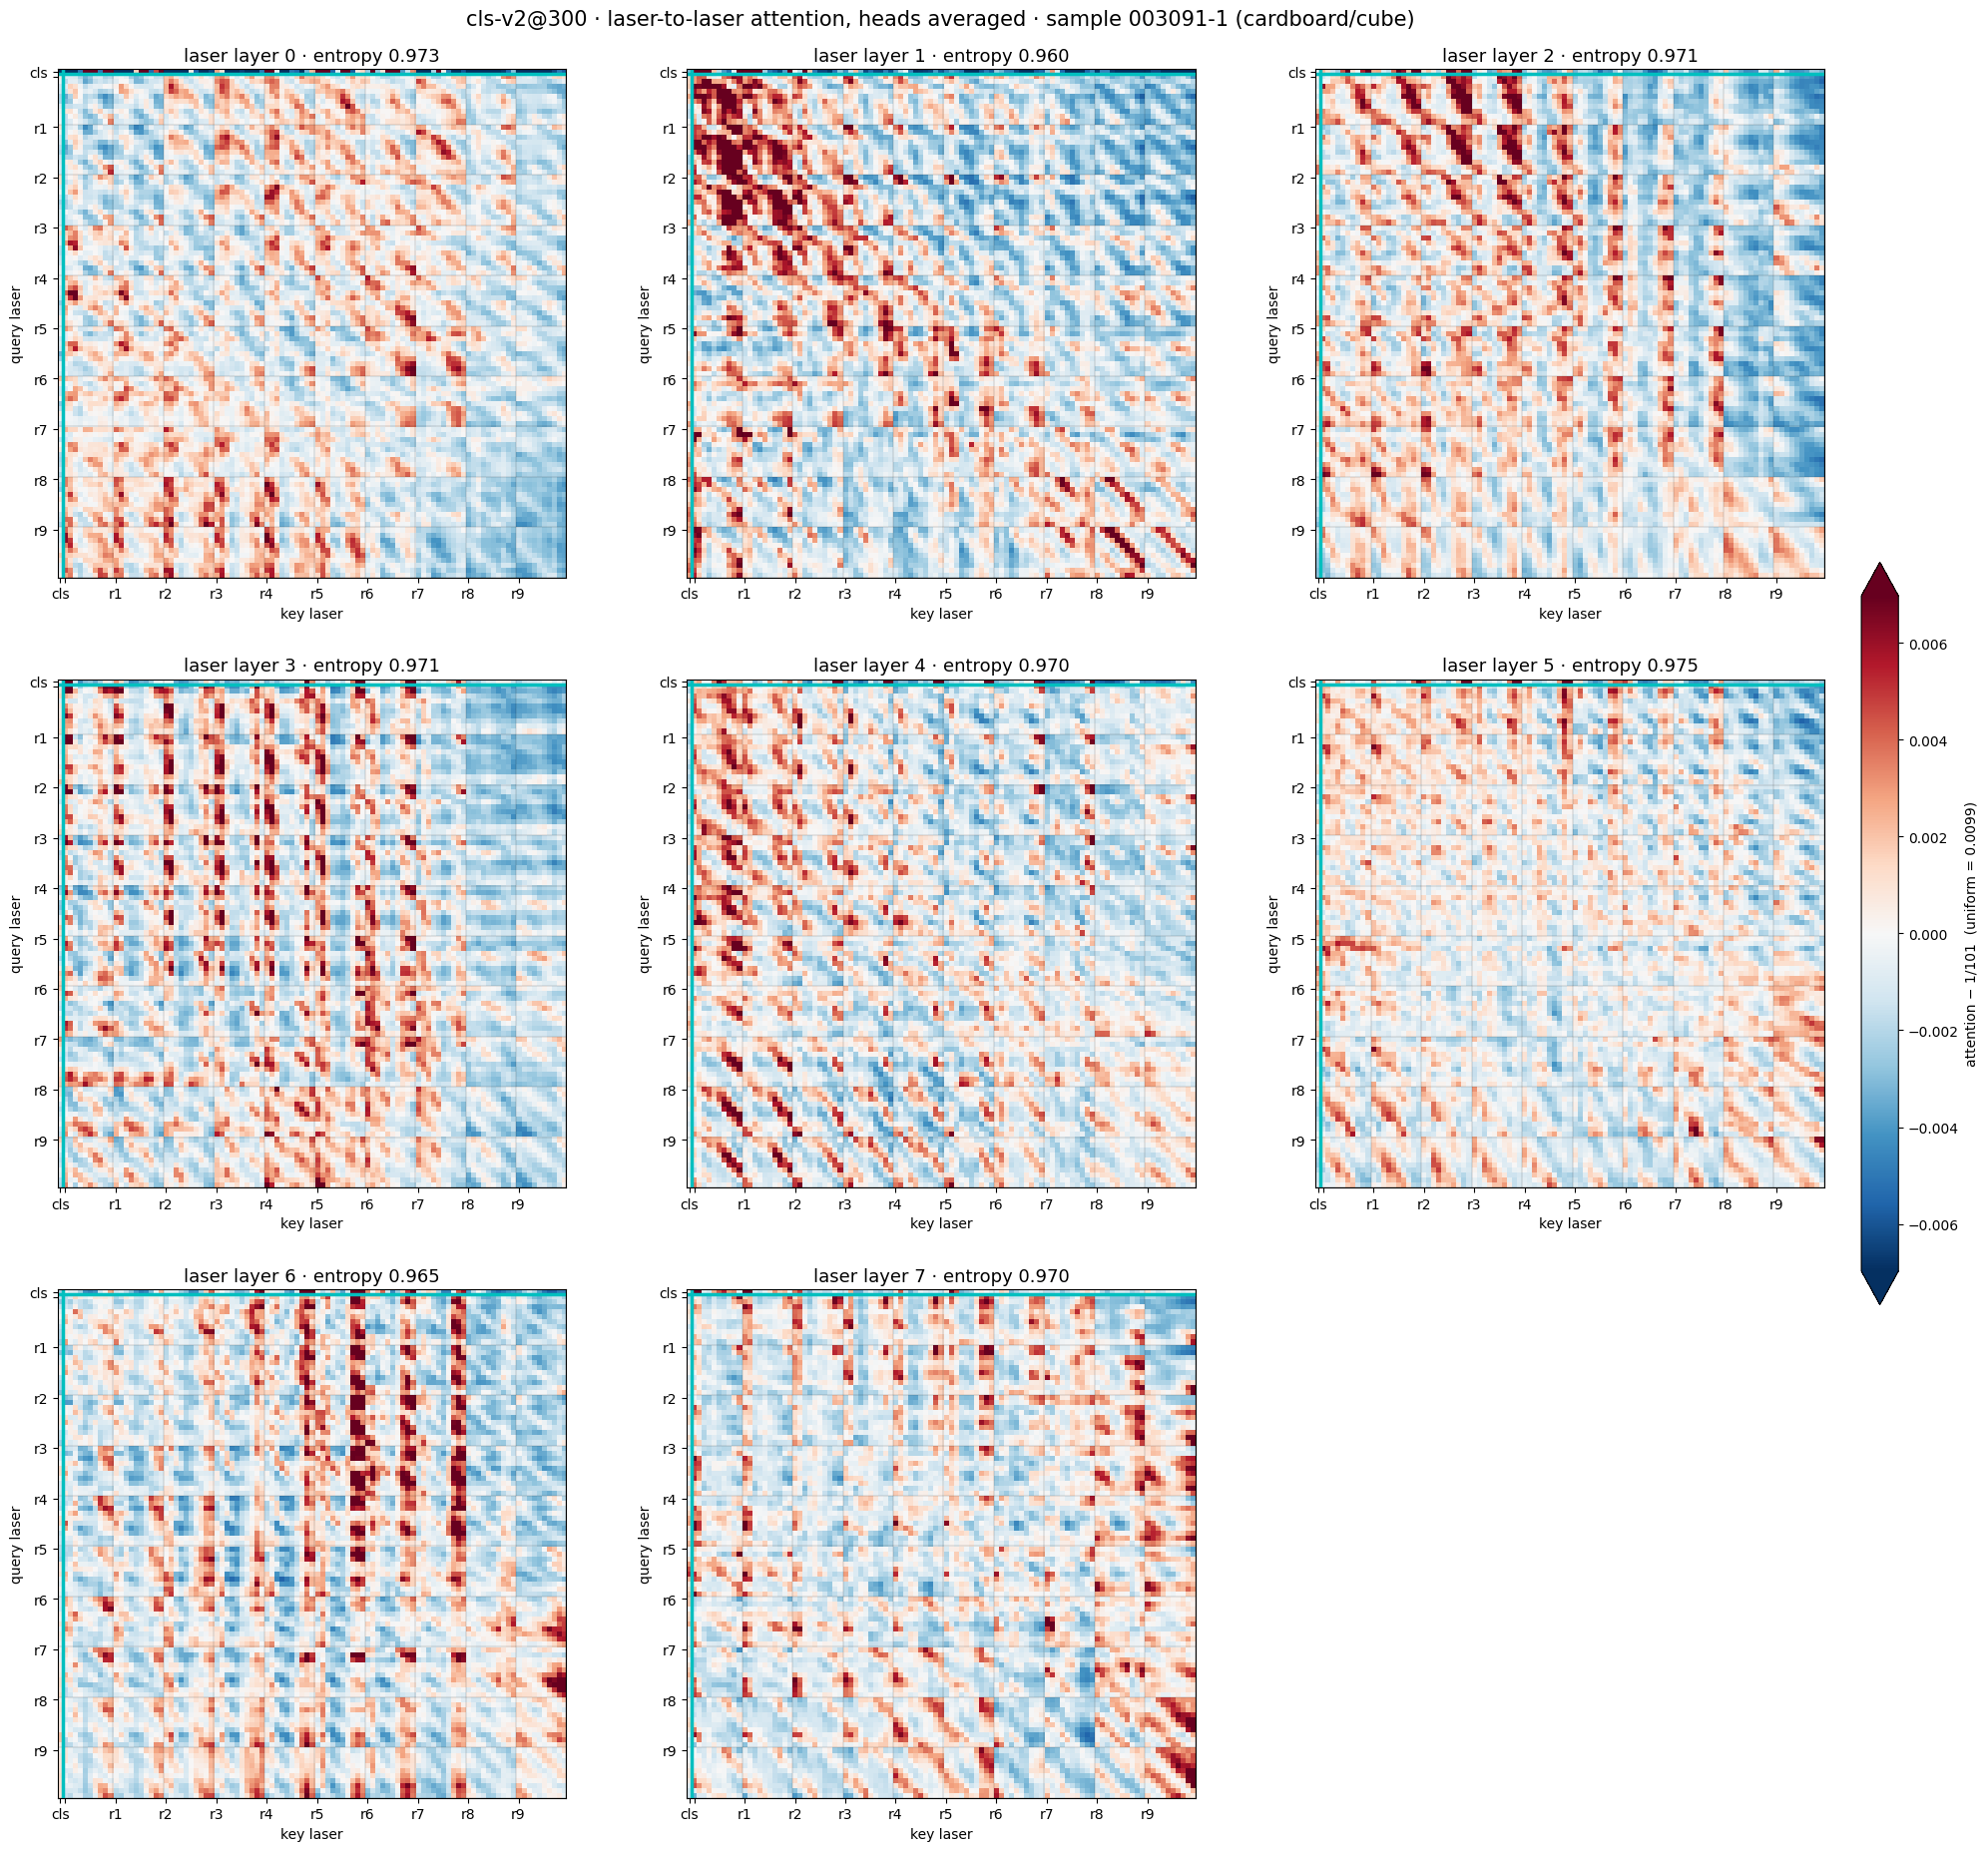

In [5]:
from matplotlib.colors import TwoSlopeNorm
def dev_grid(maps, titles, n_keys, suptitle, size=7.5, decorate=None):
    """maps: list of 2D tensors (attention); plots maps - 1/n_keys, 3 per row, diverging colours centred at 0 with a shared robust limit"""
    devs = [m.float().numpy() - 1 / n_keys for m in maps]
    lim = float(np.percentile(np.abs(np.concatenate([d.ravel() for d in devs])), 99)) or 1e-6
    nrow = math.ceil(len(devs) / 3)
    fig, axs = plt.subplots(nrow, 3, figsize=(3 * size + 1.5, size * nrow), squeeze=False)
    for j, (d, t) in enumerate(zip(devs, titles)):
        ax = axs.flat[j]
        im = ax.imshow(d, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), interpolation="nearest")
        ax.set_title(t, fontsize=13)
        if decorate: decorate(ax, j)
    for ax in axs.flat[len(devs):]: ax.axis("off")
    fig.colorbar(im, ax=axs, shrink=.6, fraction=.02, pad=.02, extend="both", label=f"attention − 1/{n_keys}  (uniform = {1 / n_keys:.4f})")
    fig.canvas.draw(); y1 = max(ax.get_position().y1 for ax in axs.flat[:len(devs)])  # top of the (aspect-shrunk) panels
    fig.suptitle(suptitle, fontsize=15, y=y1 + 0.6 / (size * nrow)); plt.show()

def laser_axes(ax, j):
    for g in range(CLS, NL + CLS + 1, C): ax.axhline(g - .5, color="k", lw=.3, alpha=.4); ax.axvline(g - .5, color="k", lw=.3, alpha=.4)
    if CLS: ax.axhline(.5, color="c", lw=2.5); ax.axvline(.5, color="c", lw=2.5)   # cls | lasers
    ticks = [CLS + r * C for r in range(R)]
    lab = (["cls"] if CLS else []) + [f"r{r}" if r or not CLS else "" for r in range(R)]   # cls sits right next to r0: drop the r0 label
    ax.set_xticks(([0] if CLS else []) + ticks, lab); ax.set_yticks(([0] if CLS else []) + ticks, lab)
    ax.set_xlabel("key laser"); ax.set_ylabel("query laser")

T_L = NL + CLS
if HEADS == "mean":
    dev_grid([a.mean(0) for a in L_ATT], [f"laser layer {l} · entropy {L_ENT[:, l].mean():.3f}" for l in range(len(L_ATT))], T_L,
             f"{TAG} · laser-to-laser attention, heads averaged · {WHAT}", decorate=laser_axes)
else:
    for l, a in enumerate(L_ATT):
        dev_grid(list(a), [f"layer {l} · head {h} · entropy {L_ENT[:, l, h].mean():.3f}" for h in range(len(a))], T_L,
                 f"{TAG} · laser layer {l}, every head · {WHAT}", size=6, decorate=laser_axes)

## 3 · laser stage, spatial: where each query laser looks
One figure per query laser (green square = the query) and one for the attention each laser receives (mean over all queries); panels = layers, heads averaged.
Same deviation-from-uniform colours (shared robust limit per figure). With [cls]: titles give the query's weight on the cls key.

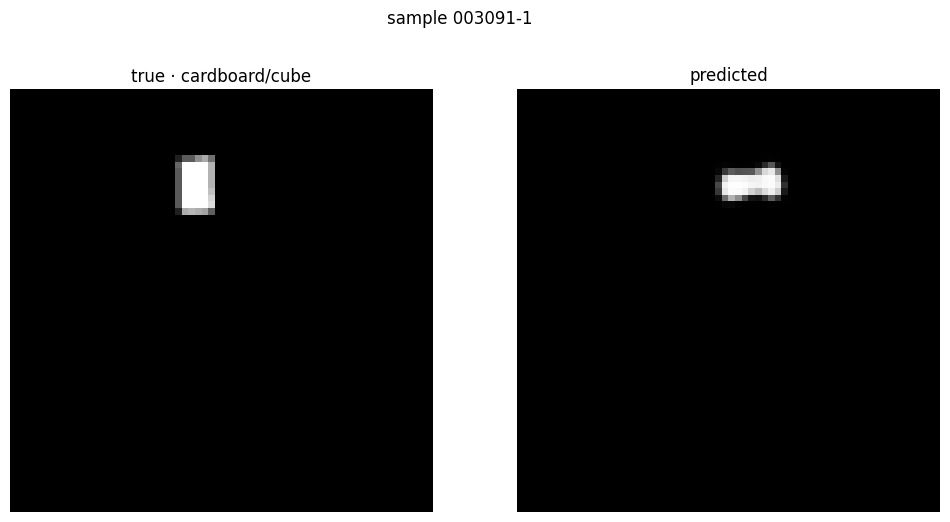

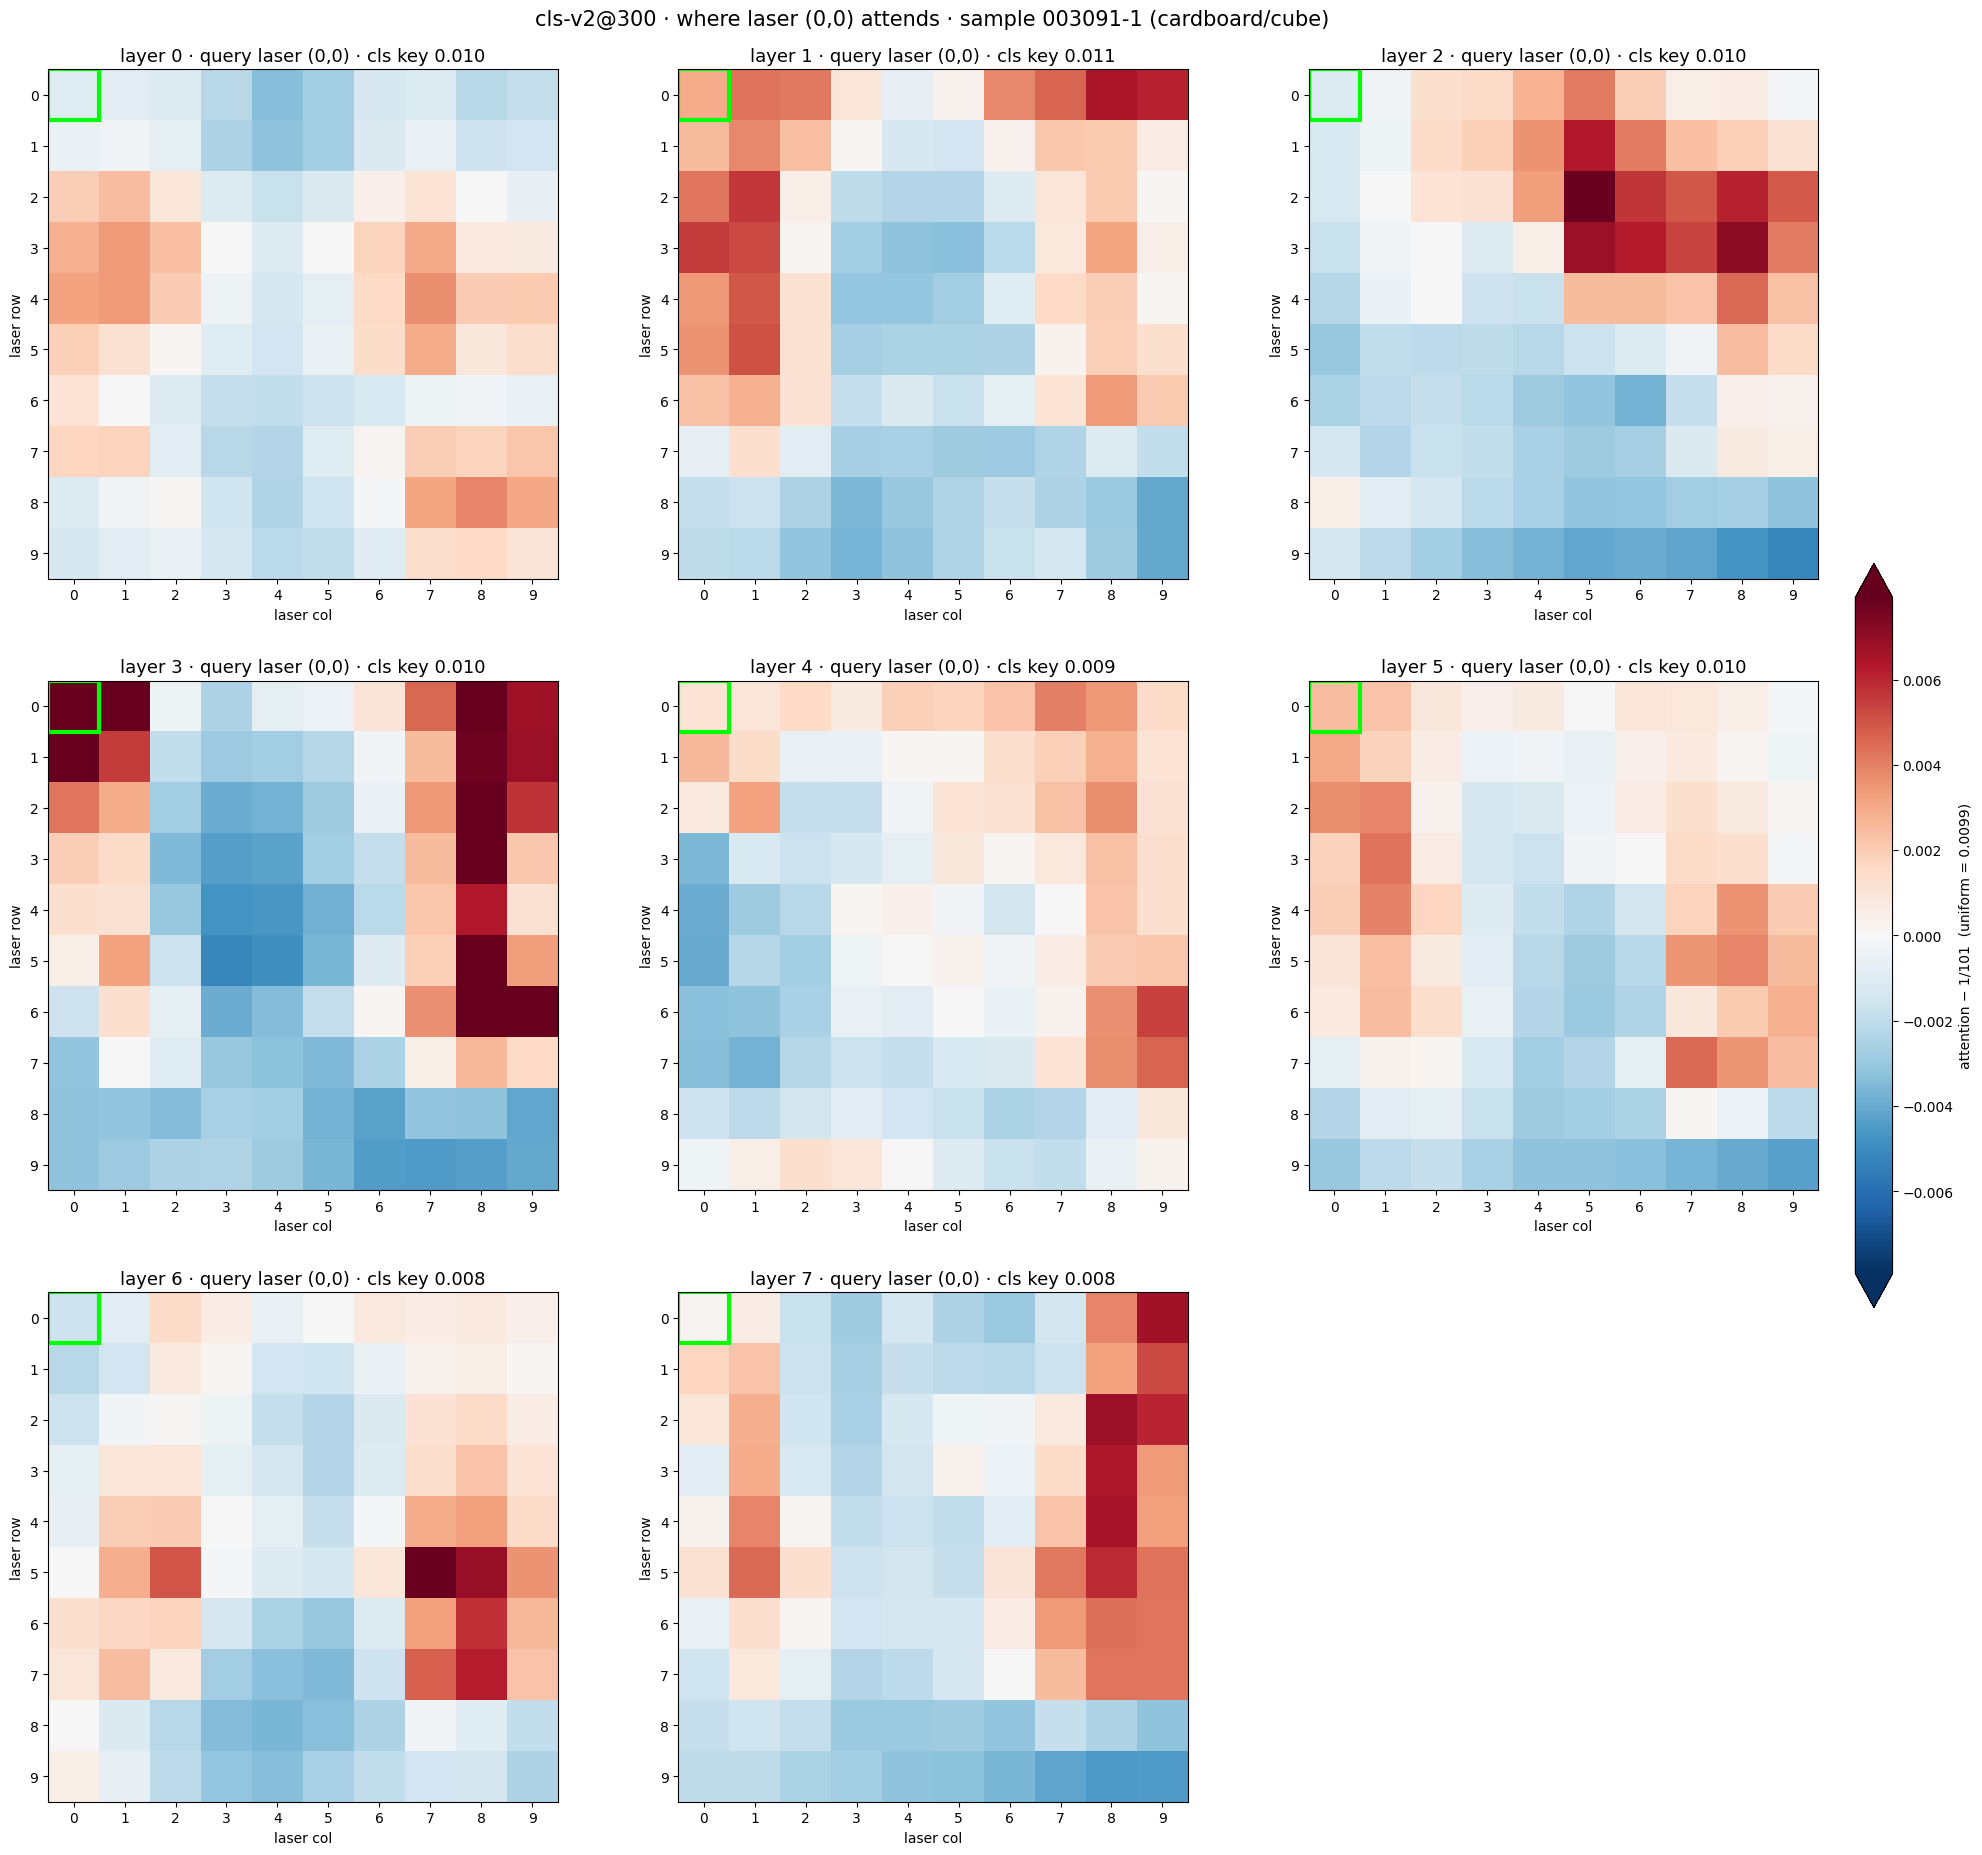

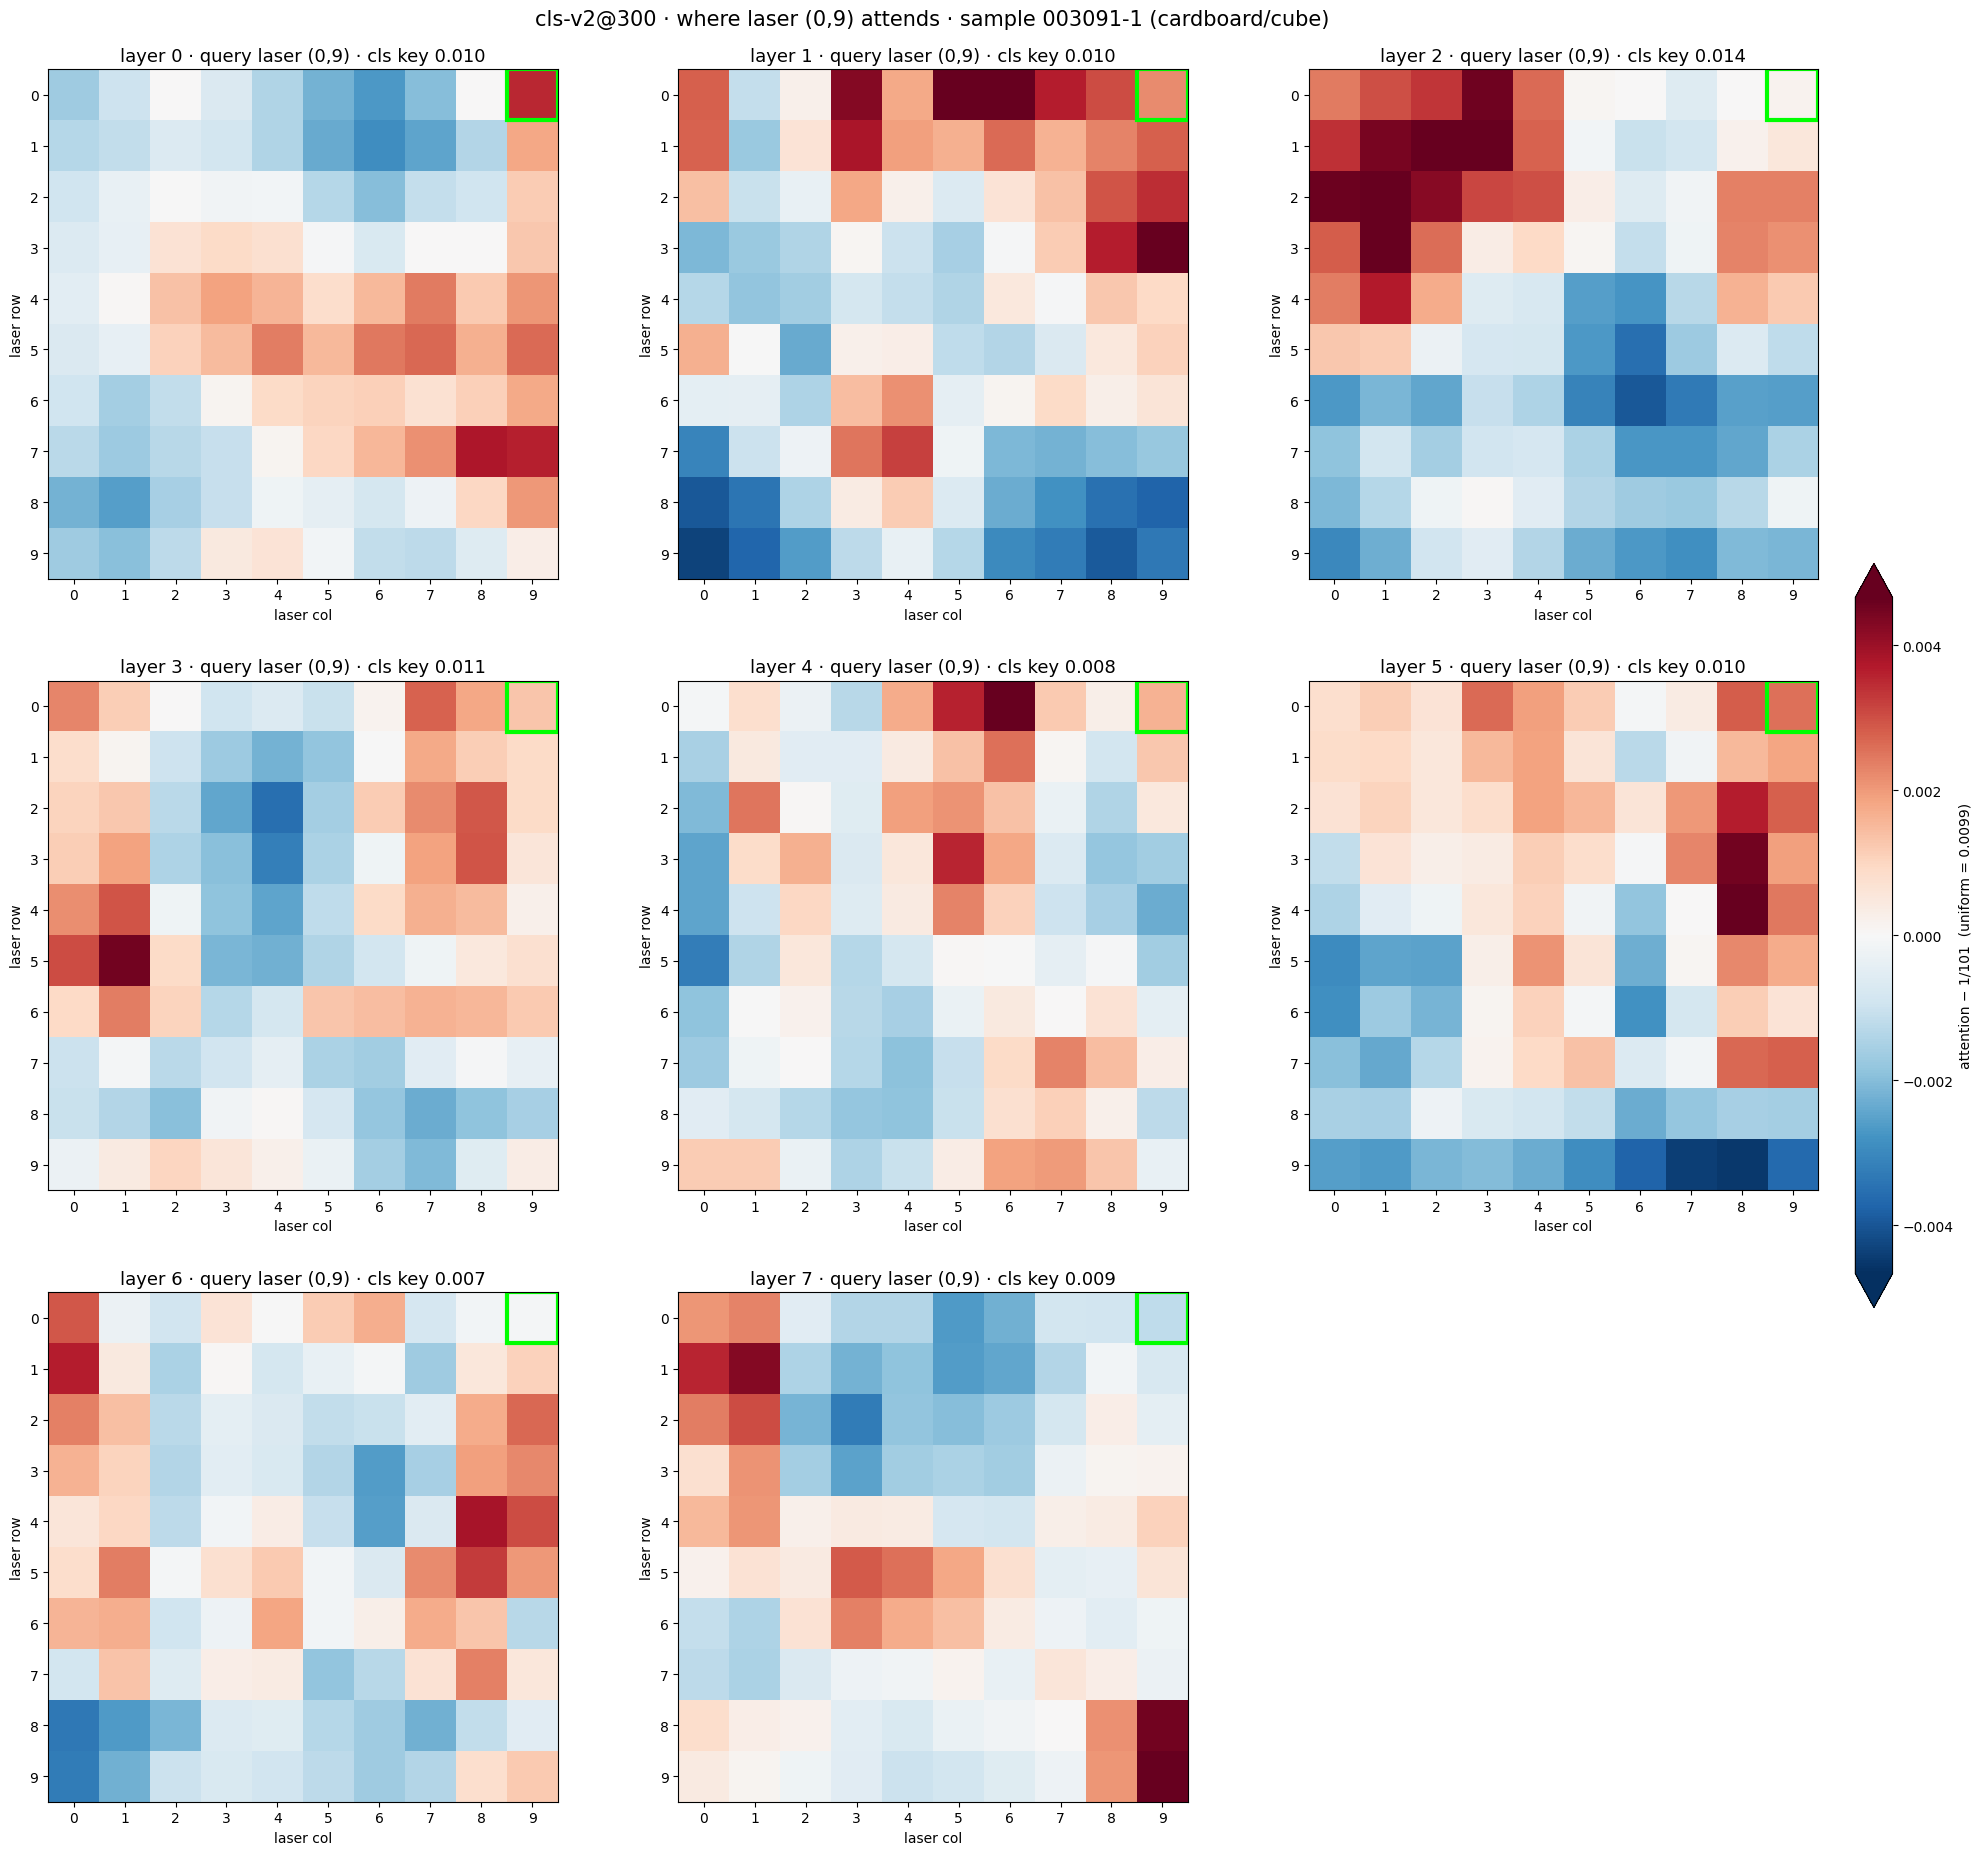

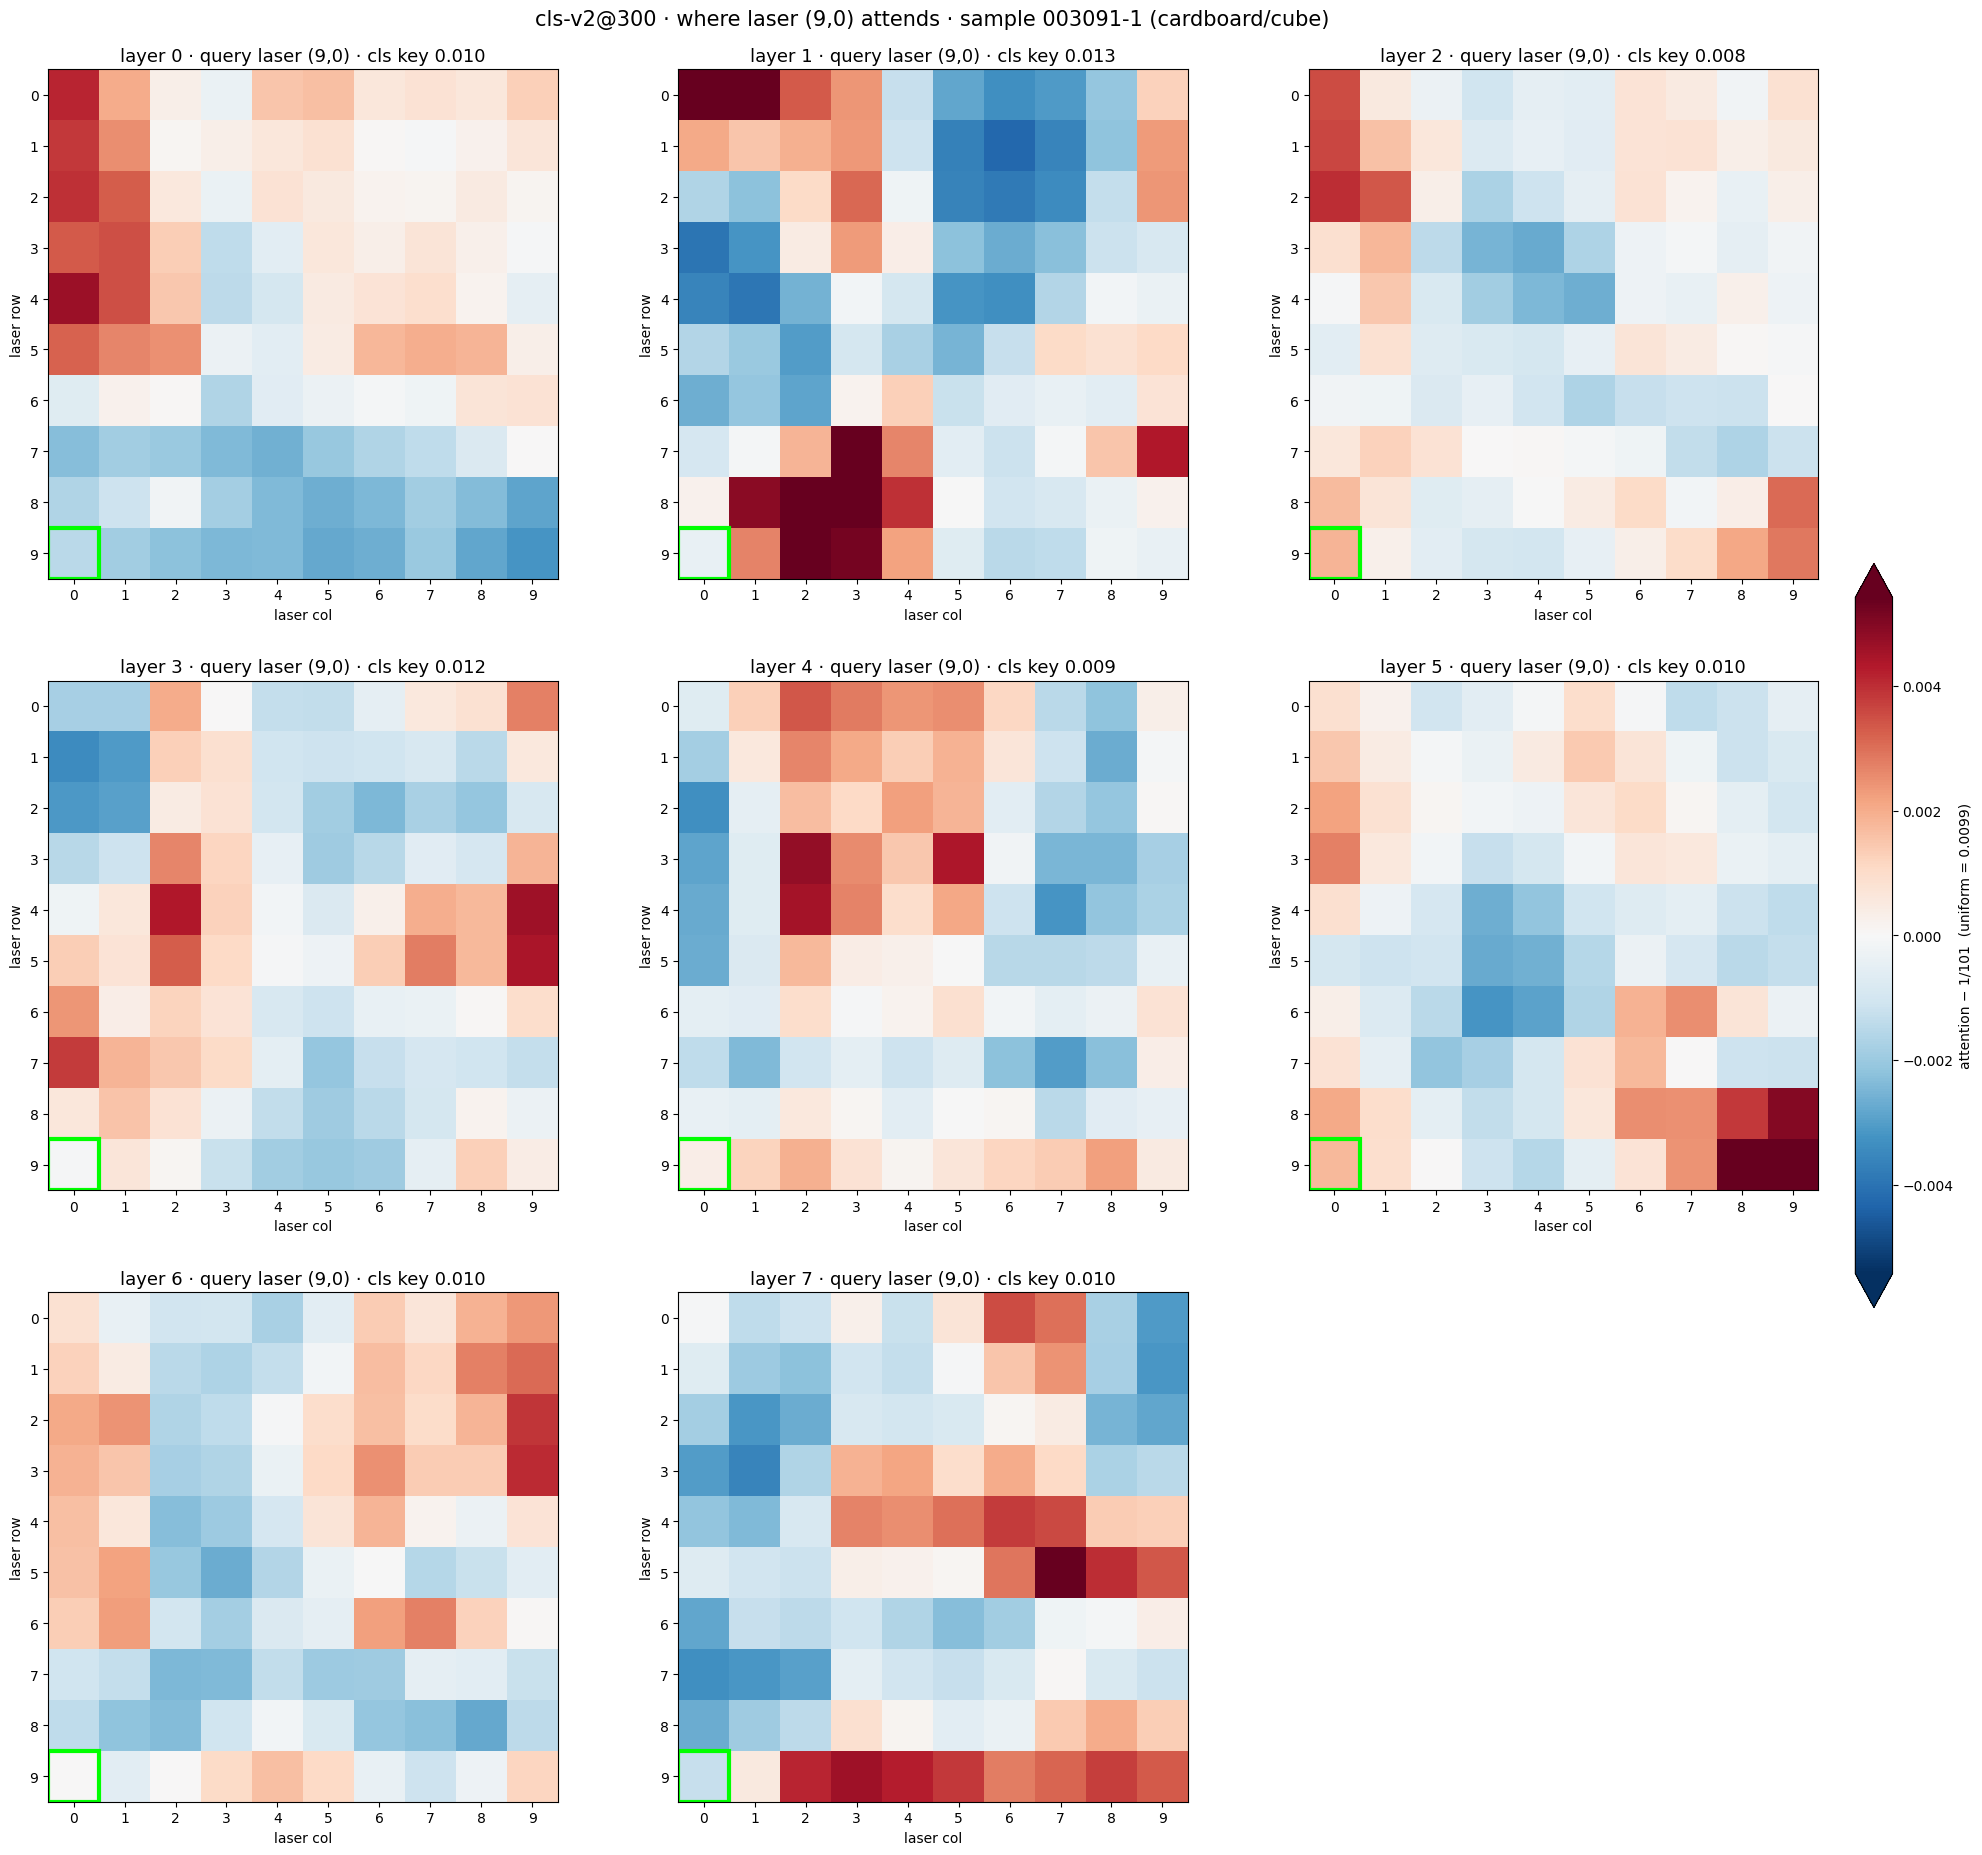

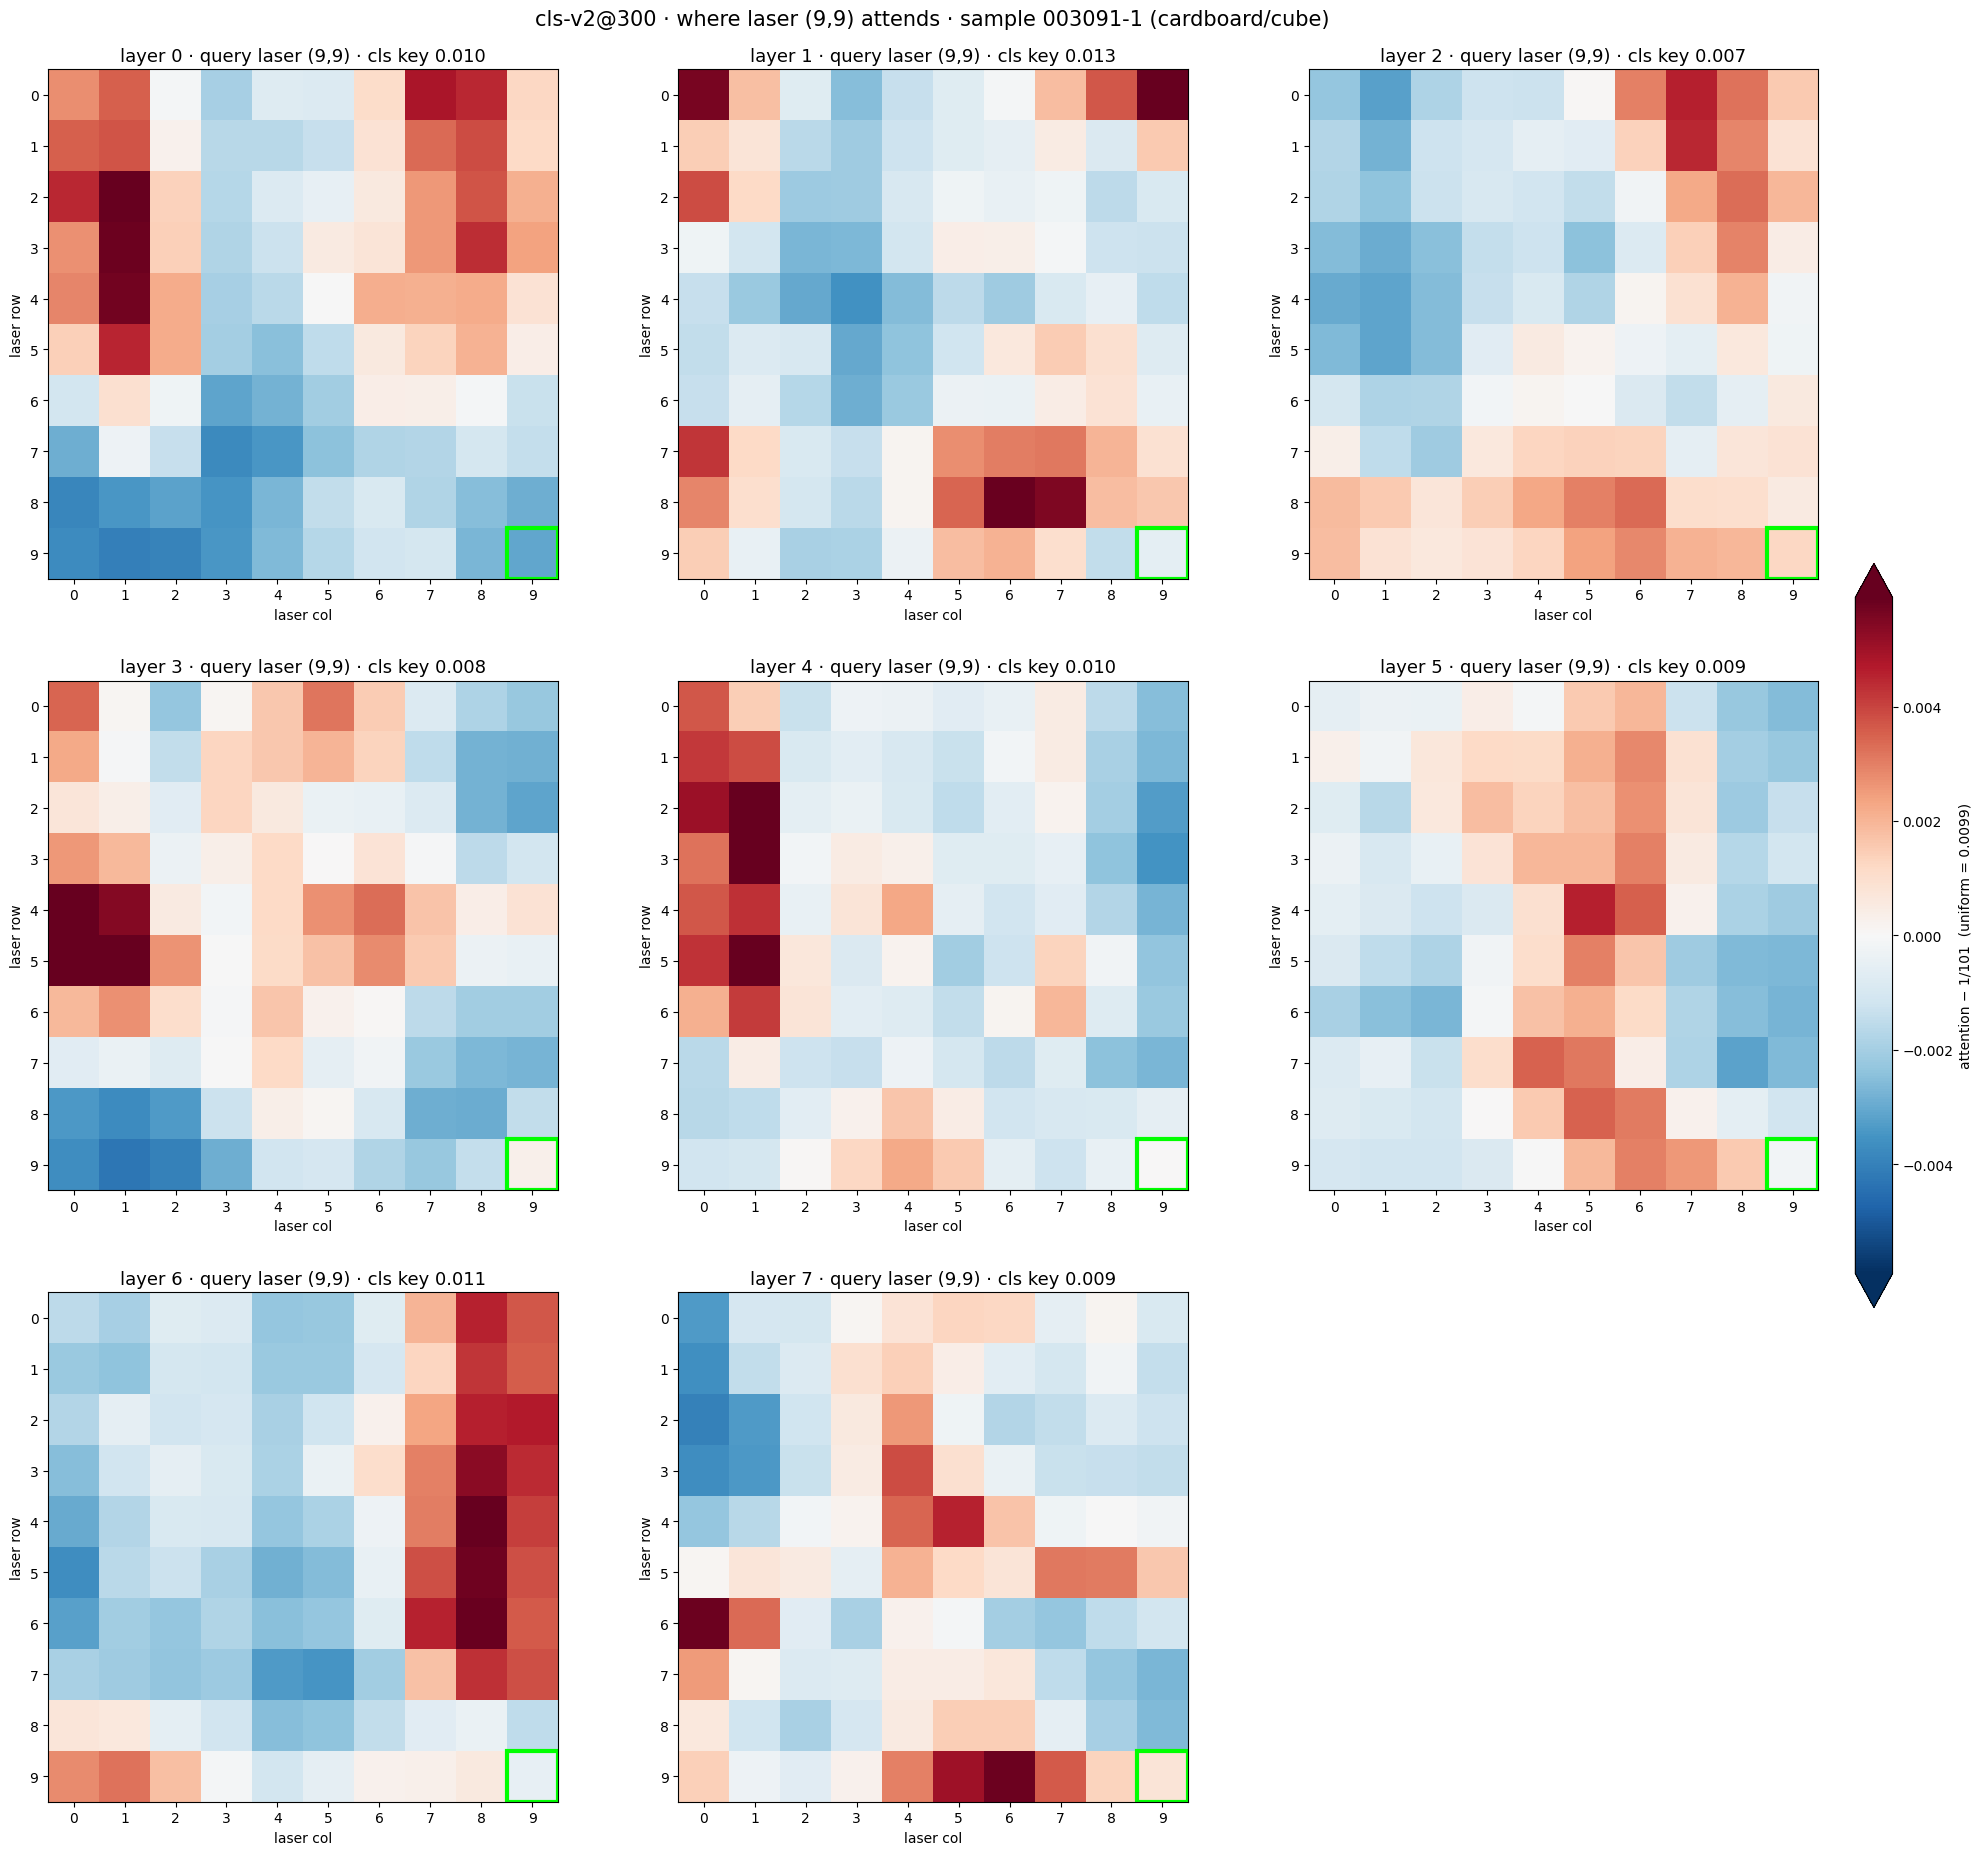

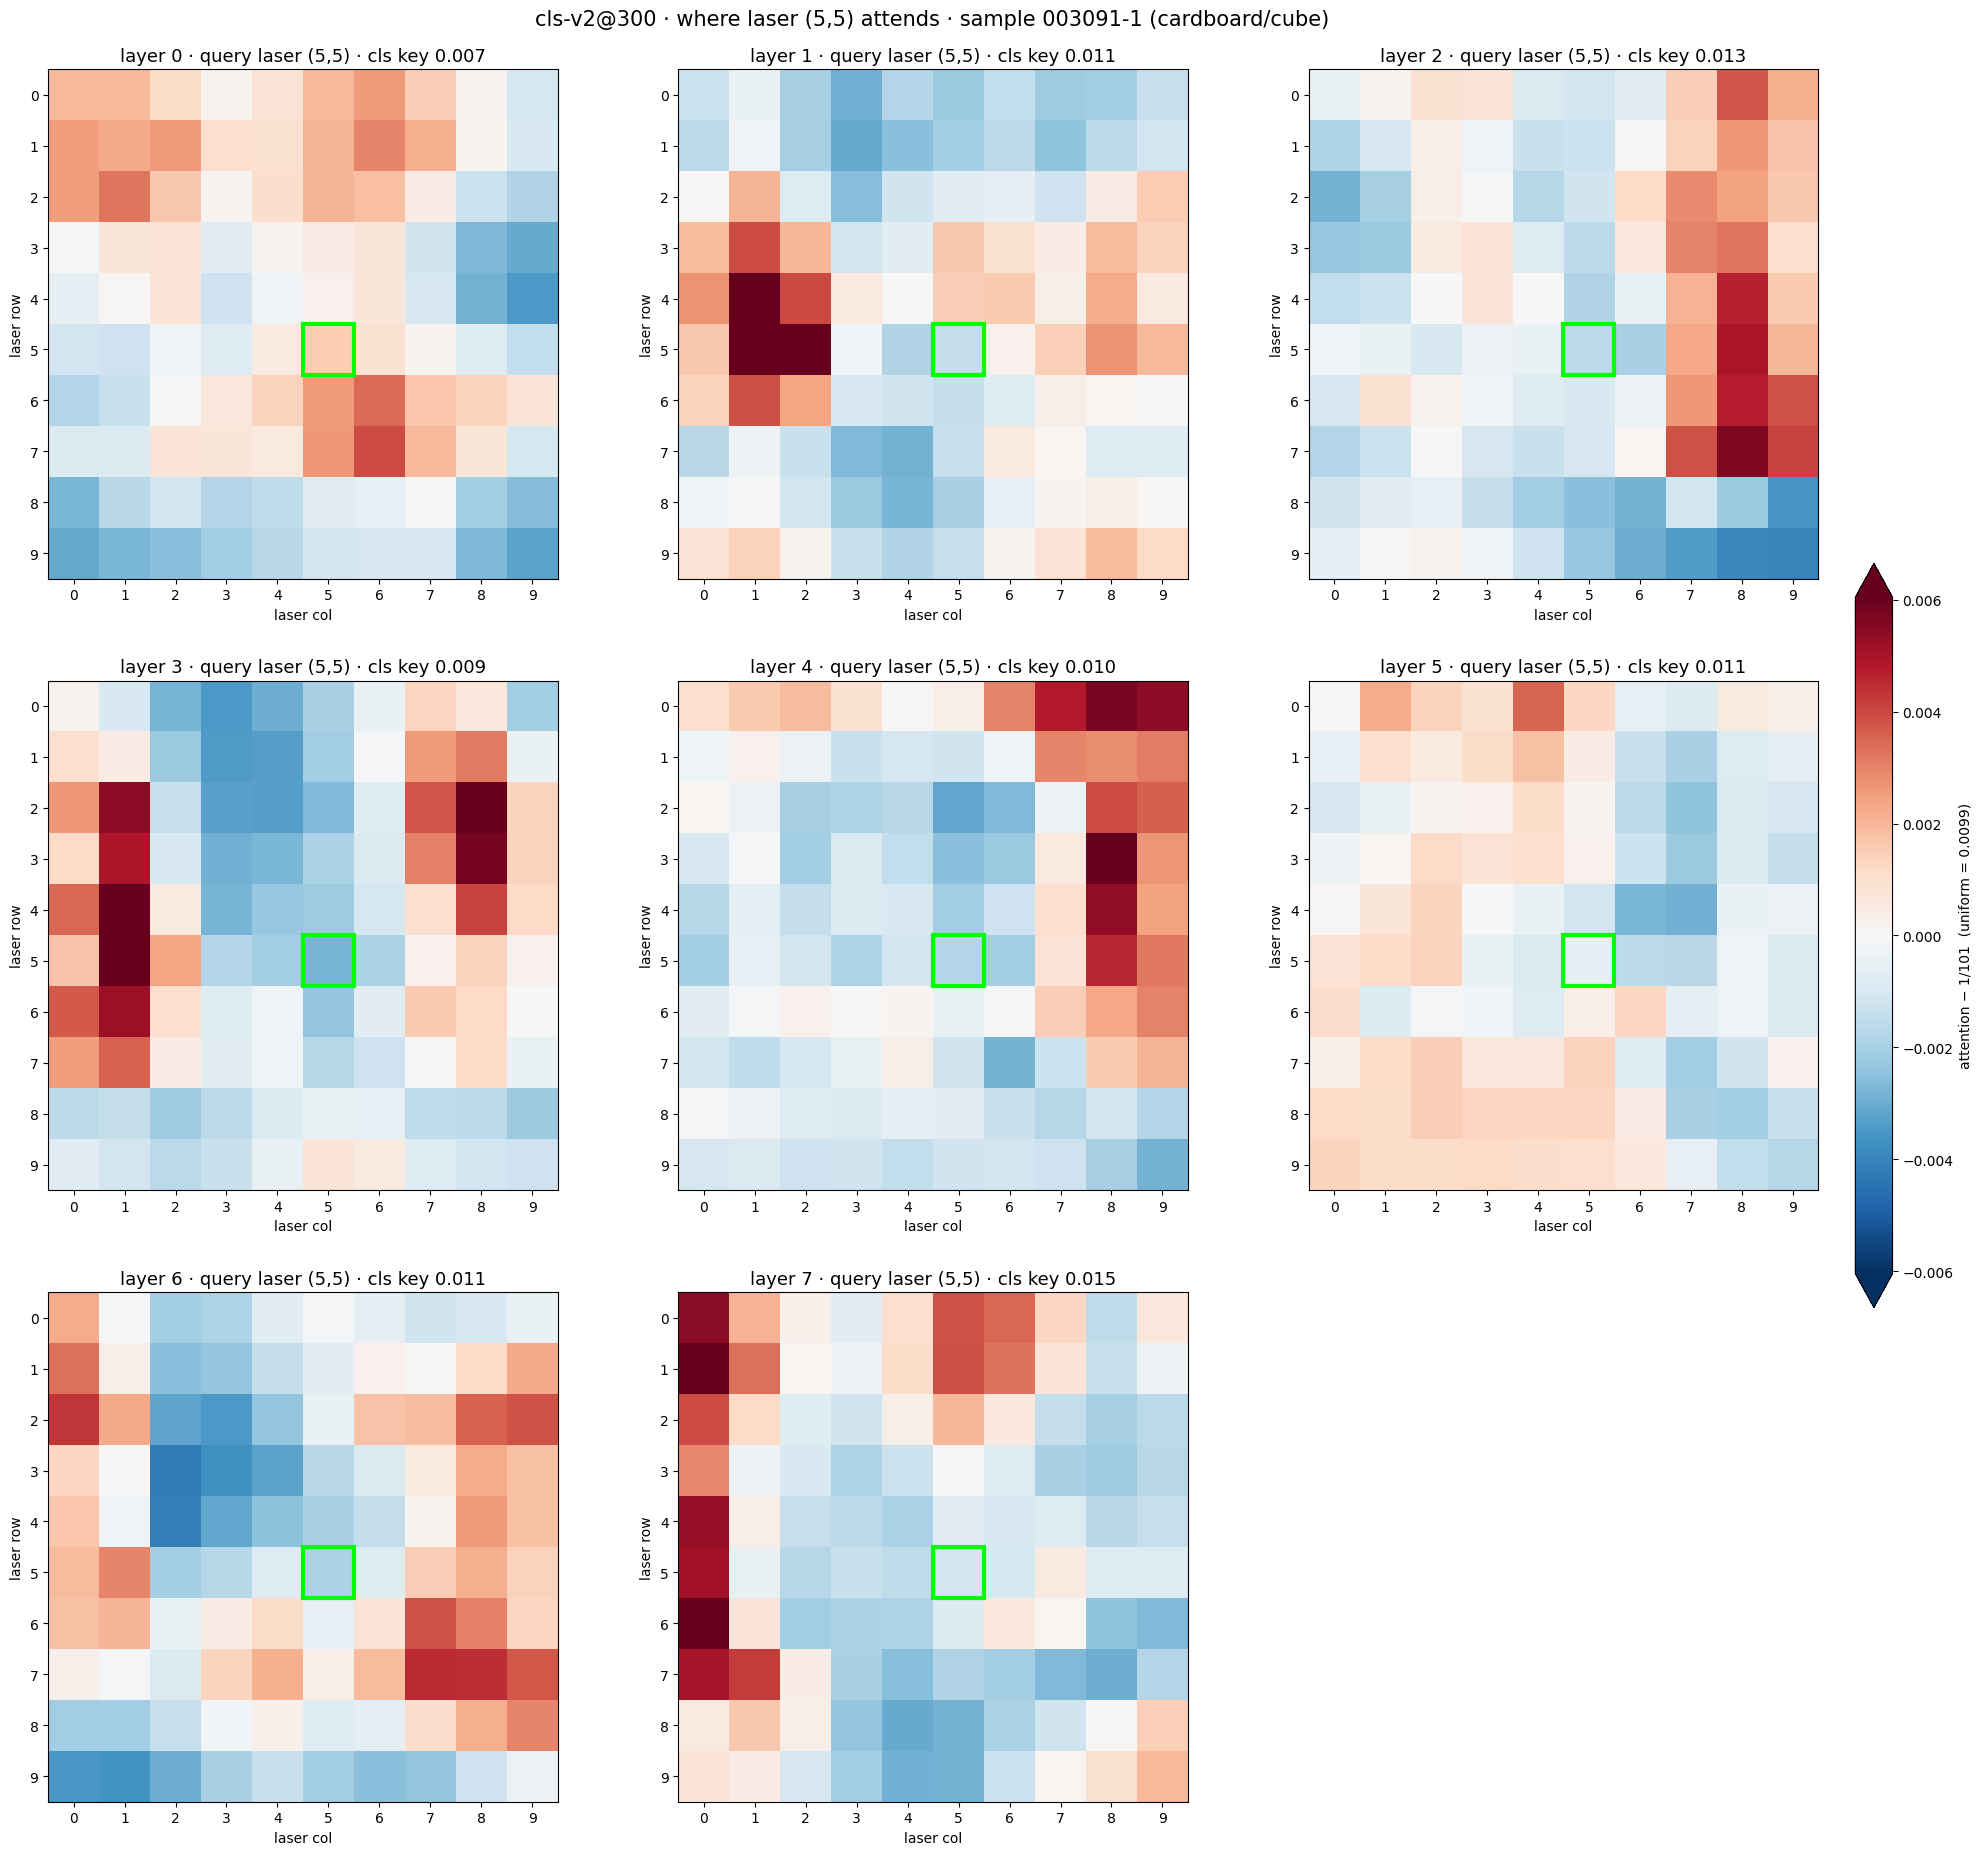

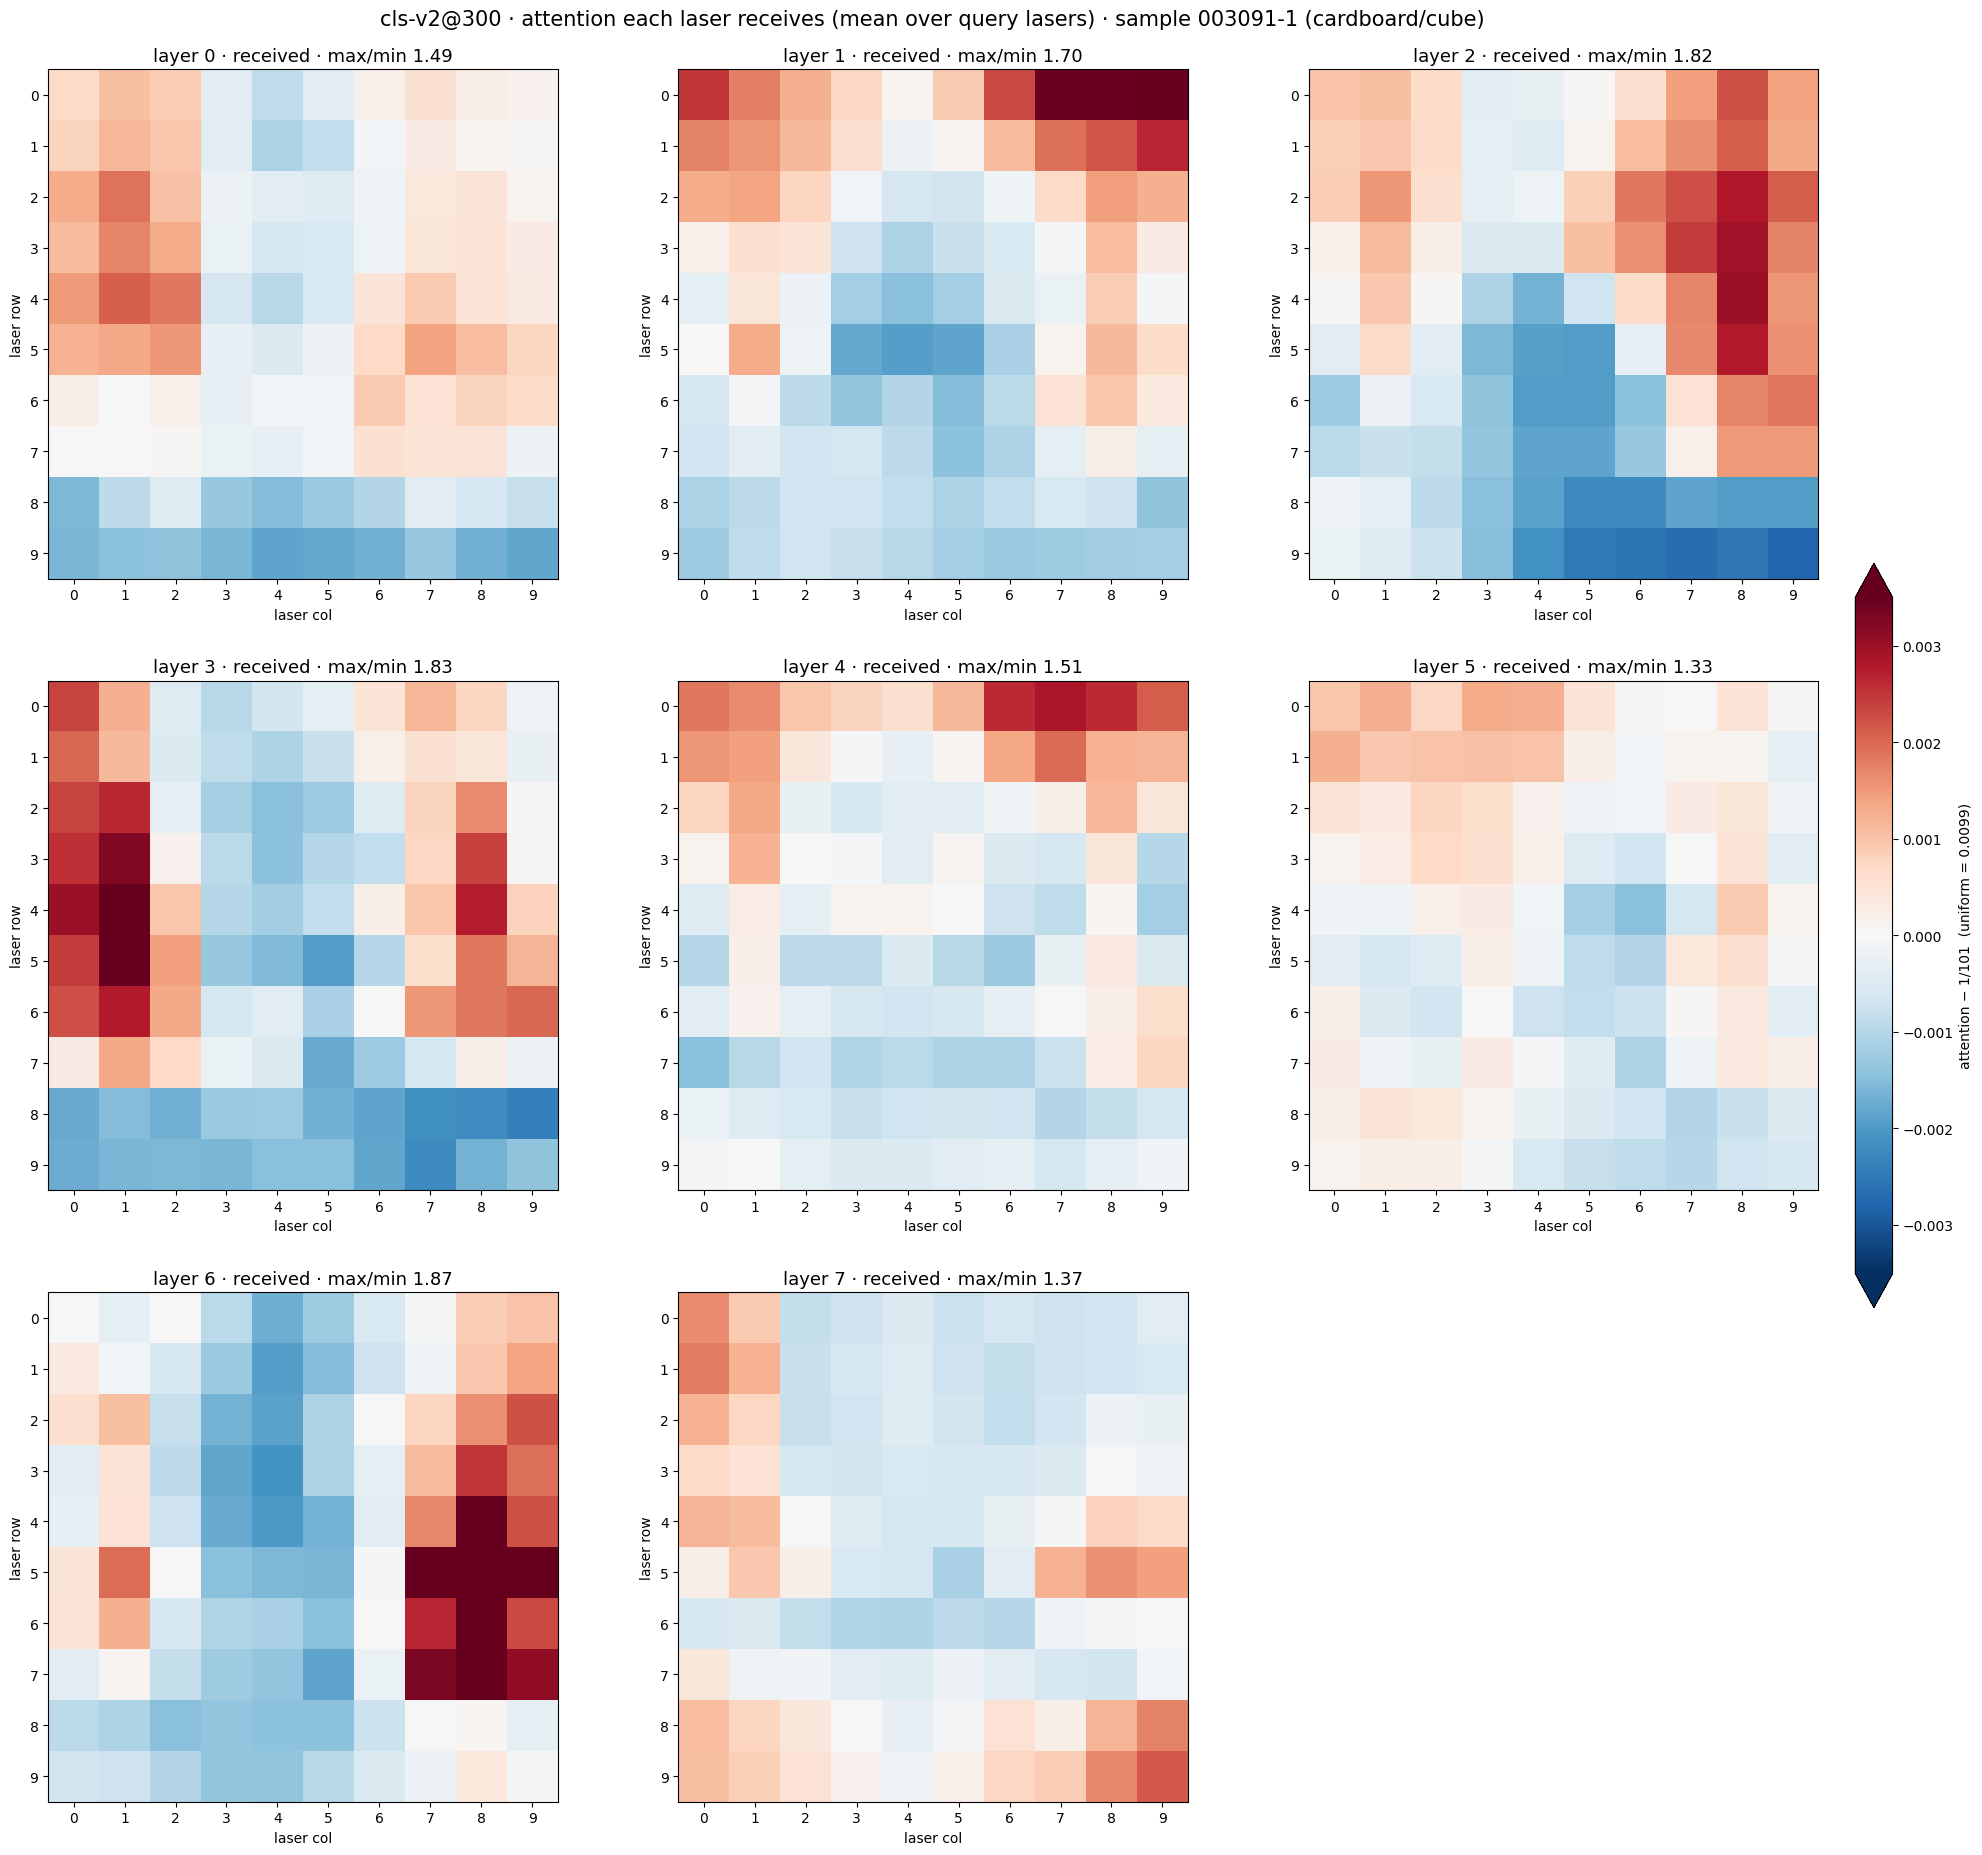

In [6]:
if not ALL_EVAL:
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    for ax, (t, img) in zip(axs, [("true · " + split0, y_true), ("predicted", y_pred)]): ax.imshow(img, cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")
    fig.suptitle(f"sample {SAMPLE}"); plt.show()

def grid_axes(mark=None):
    def f(ax, j):
        ax.set_xticks(range(C)); ax.set_yticks(range(R)); ax.set_xlabel("laser col"); ax.set_ylabel("laser row")
        if mark: ax.add_patch(plt.Rectangle((mark[1] - .5, mark[0] - .5), 1, 1, fill=False, ec="lime", lw=3))
    return f
M = [a.mean(0) for a in L_ATT]                                    # per layer (T,T), heads averaged
for r, c in QUERY_LASERS:
    q = CLS + r * C + c
    dev_grid([m[q, CLS:].view(R, C) for m in M], [f"layer {l} · query laser ({r},{c})" + (f" · cls key {float(m[q, 0]):.3f}" if CLS else "") for l, m in enumerate(M)],
             T_L, f"{TAG} · where laser ({r},{c}) attends · {WHAT}", decorate=grid_axes((r, c)))
recv = [m[CLS:, CLS:].mean(0).view(R, C) for m in M]
dev_grid(recv, [f"layer {l} · received · max/min {float(v.max() / v.min()):.2f}" for l, v in enumerate(recv)],
         T_L, f"{TAG} · attention each laser receives (mean over query lasers) · {WHAT}", decorate=grid_axes())

## 3b · [cls] token (only `--readout cls` runs)
Per layer (heads averaged). Freq: what [cls] attends to over the 18 bands, and how much each band gives to [cls] (mean over lasers). Laser: same on the 10x10 grid. Titles: [cls] self-attention.

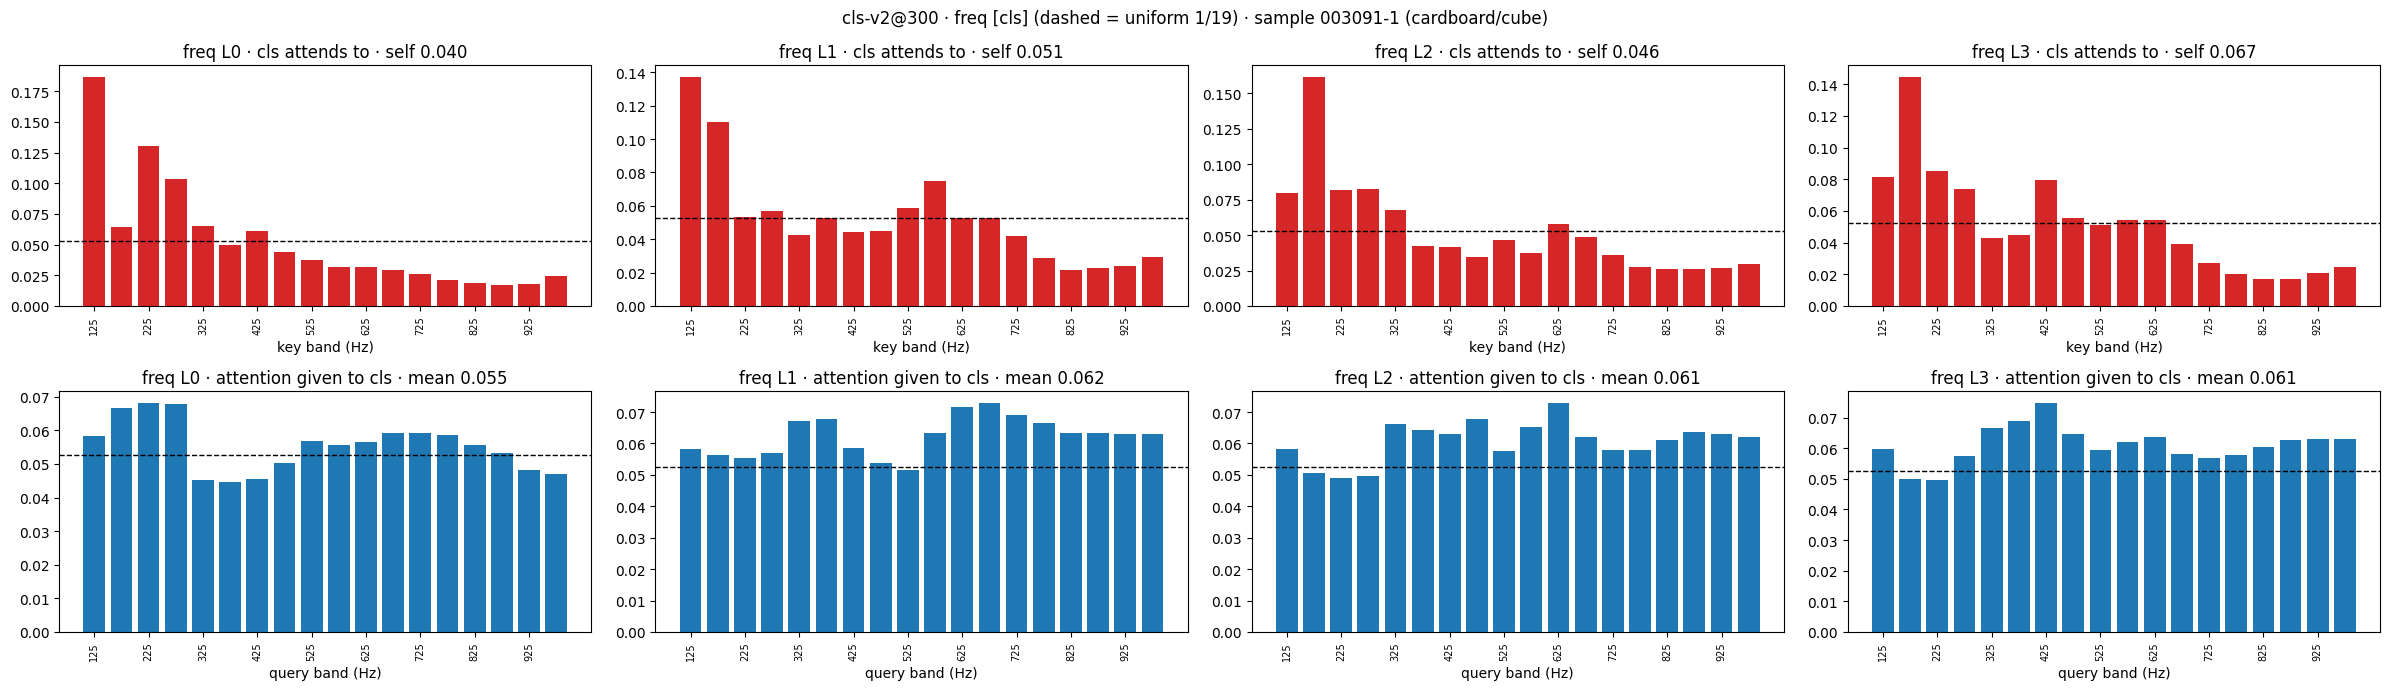

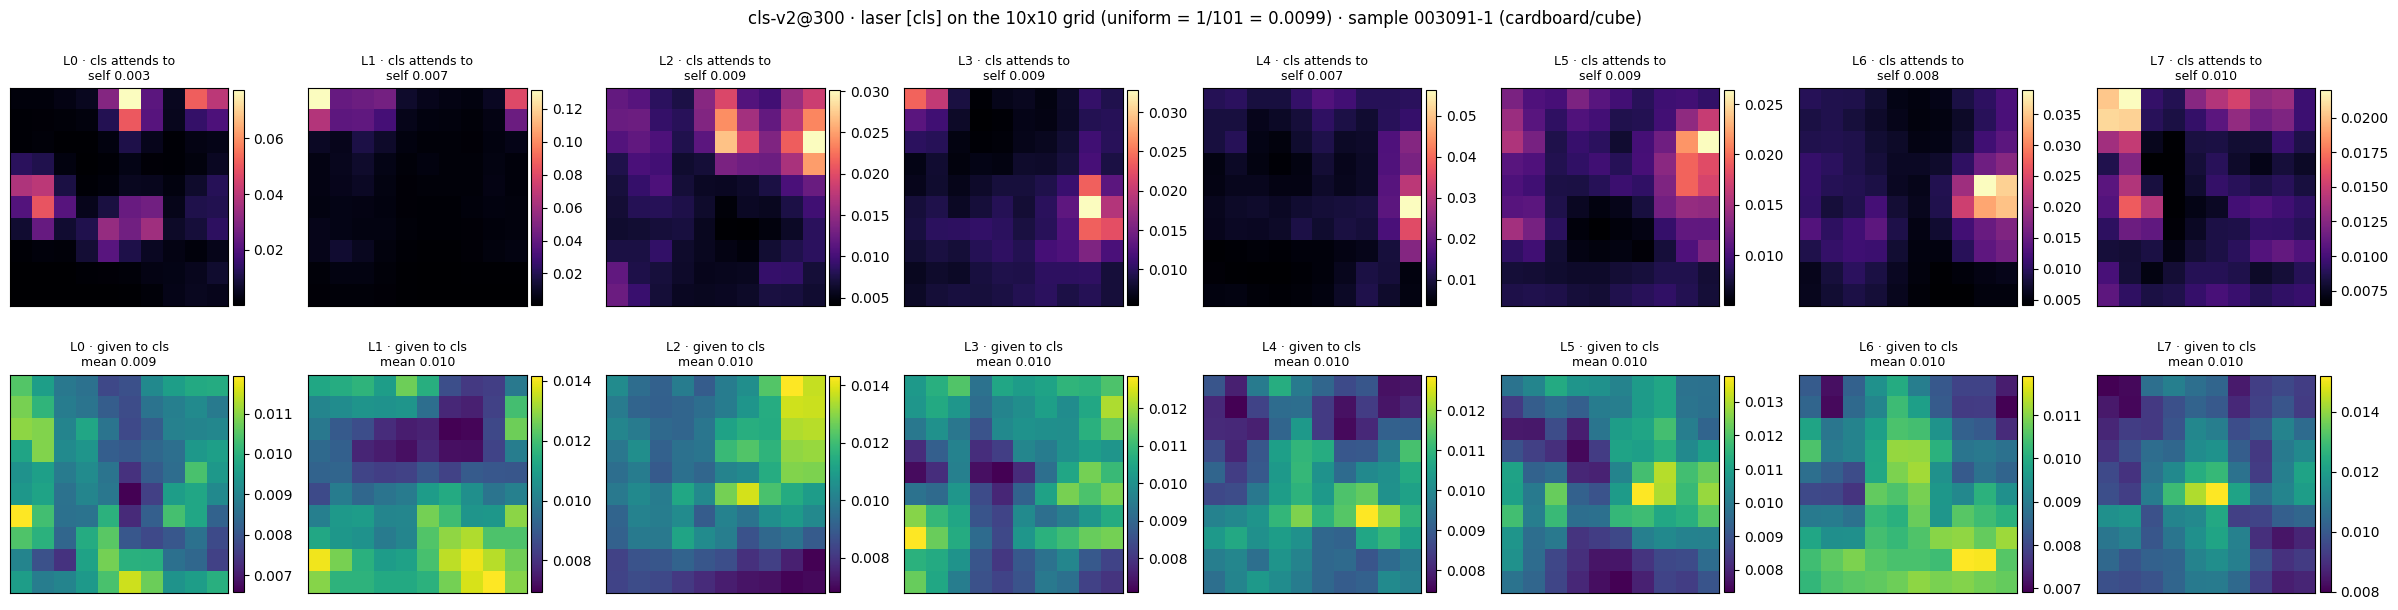

In [7]:
if not CLS: print("no [cls] token in this run (readout = per): nothing to show")
else:
    fig, axs = plt.subplots(2, len(F_ATT), figsize=(6 * len(F_ATT), 7), squeeze=False)
    for l, a in enumerate(F_ATT):
        m = a.mean(0)
        axs[0, l].bar(range(NB), m[0, 1:].numpy(), color="C3"); axs[0, l].set_title(f"freq L{l} · cls attends to · self {float(m[0, 0]):.3f}")
        axs[1, l].bar(range(NB), m[1:, 0].numpy(), color="C0"); axs[1, l].set_title(f"freq L{l} · attention given to cls · mean {float(m[1:, 0].mean()):.3f}")
        for ax, u in [(axs[0, l], 1 / (NB + 1)), (axs[1, l], 1 / (NB + 1))]:
            ax.axhline(u, color="k", ls="--", lw=1); ax.set_xticks(range(0, NB, 2), band_lab[1::2], rotation=90, fontsize=7)
        axs[0, l].set_xlabel("key band (Hz)"); axs[1, l].set_xlabel("query band (Hz)")
    fig.suptitle(f"{TAG} · freq [cls] (dashed = uniform 1/{NB + 1}) · {WHAT}"); plt.tight_layout(); plt.show()

    fig, axs = plt.subplots(2, len(L_ATT), figsize=(3 * len(L_ATT), 6.4), squeeze=False)
    for l, a in enumerate(L_ATT):
        m = a.mean(0)
        im0 = axs[0, l].imshow(m[0, 1:].view(R, C), cmap="magma", interpolation="nearest"); axs[0, l].set_title(f"L{l} · cls attends to\nself {float(m[0, 0]):.3f}", fontsize=9)
        im1 = axs[1, l].imshow(m[1:, 0].view(R, C), cmap="viridis", interpolation="nearest"); axs[1, l].set_title(f"L{l} · given to cls\nmean {float(m[1:, 0].mean()):.3f}", fontsize=9)
        fig.colorbar(im0, ax=axs[0, l], fraction=.046, pad=.02); fig.colorbar(im1, ax=axs[1, l], fraction=.046, pad=.02)
    for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{TAG} · laser [cls] on the 10x10 grid (uniform = 1/{NL + 1} = {1 / (NL + 1):.4f}) · {WHAT}"); plt.tight_layout(); plt.show()

## 4 · attention entropy per layer
Mean over queries of the row entropy / log(n keys), per head then averaged: 1 = uniform, 0 = one-hot. Freq: every run (solid = band queries, dashed = [cls] query).
Laser: last run; thin lines = heads, red = [cls] query. Band (ALL_EVAL) = 10-90% over samples. y-axis zoomed.

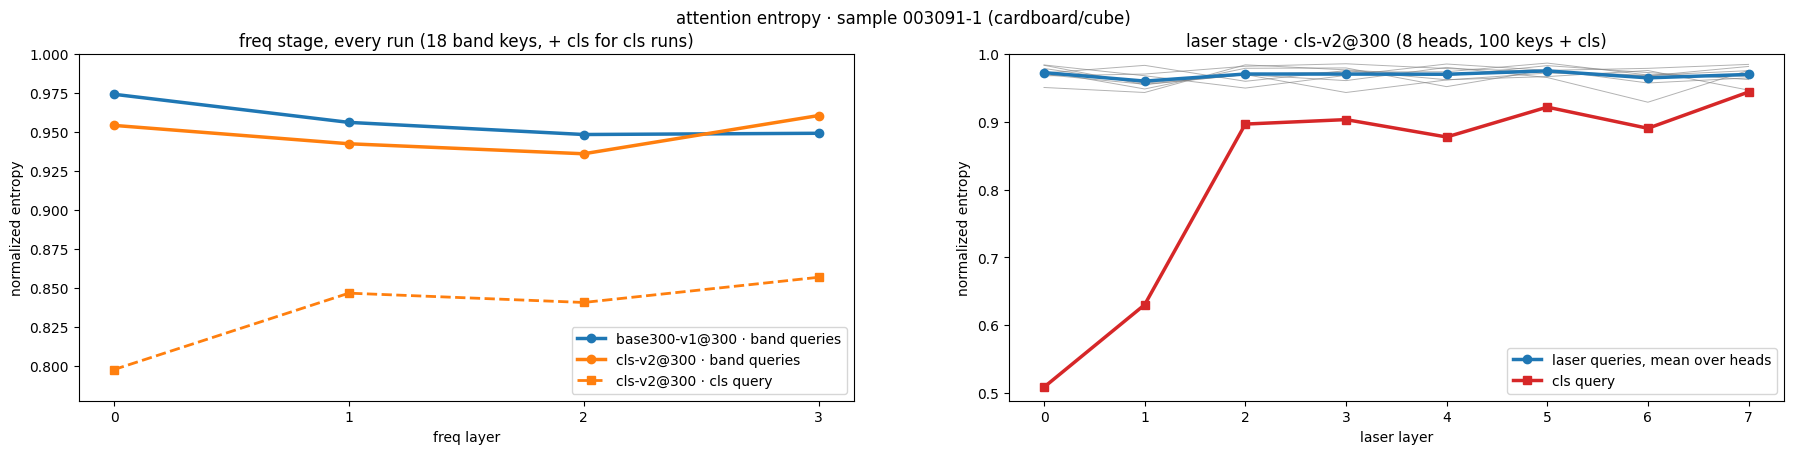

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(22, 4.5))
ax, lows = axs[0], []
for k, r in enumerate(RES.values()):
    E, x = r["F_ENT"], np.arange(r["F_ENT"].shape[1])
    ax.plot(x, E.mean((0, 2)), "o-", color=f"C{k}", lw=2.5, label=f"{r['tag']} · band queries"); lows.append(E.mean(2).min())
    if r["cls"]: ax.plot(x, r["F_ENT_CLS"].mean((0, 2)), "s--", color=f"C{k}", lw=2, label=f"{r['tag']} · cls query"); lows.append(r["F_ENT_CLS"].mean(2).min())
    if len(E) > 1: ax.fill_between(x, *np.percentile(E.mean(2), [10, 90], axis=0), color=f"C{k}", alpha=.2)
ax.set_xticks(x); ax.set_xlabel("freq layer"); ax.set_ylabel("normalized entropy"); ax.set_ylim(min(.8, min(lows) - .02), 1.0); ax.legend()
ax.set_title(f"freq stage, every run ({NB} band keys, + cls for cls runs)")
ax, E, x = axs[1], L_ENT, np.arange(L_ENT.shape[1])
for h in range(E.shape[2]): ax.plot(x, E[:, :, h].mean(0), color="gray", lw=.7, alpha=.6)
ax.plot(x, E.mean((0, 2)), "o-", color="C0", lw=2.5, label="laser queries, mean over heads")
if CLS: ax.plot(x, L_ENT_CLS.mean((0, 2)), "s-", color="C3", lw=2.5, label="cls query")
if len(E) > 1: ax.fill_between(x, *np.percentile(E.mean(2), [10, 90], axis=0), color="C0", alpha=.2, label="10-90% over samples")
ax.set_xticks(x); ax.set_xlabel("laser layer"); ax.set_ylabel("normalized entropy"); ax.legend()
ax.set_ylim(min(.8, E.mean(2).min() - .02, *([L_ENT_CLS.mean(2).min() - .02] if CLS else [])), 1.0)
ax.set_title(f"laser stage · {TAG} ({E.shape[-1]} heads, {NL} keys{' + cls' if CLS else ''})")
fig.suptitle(f"attention entropy · {WHAT}"); plt.show()